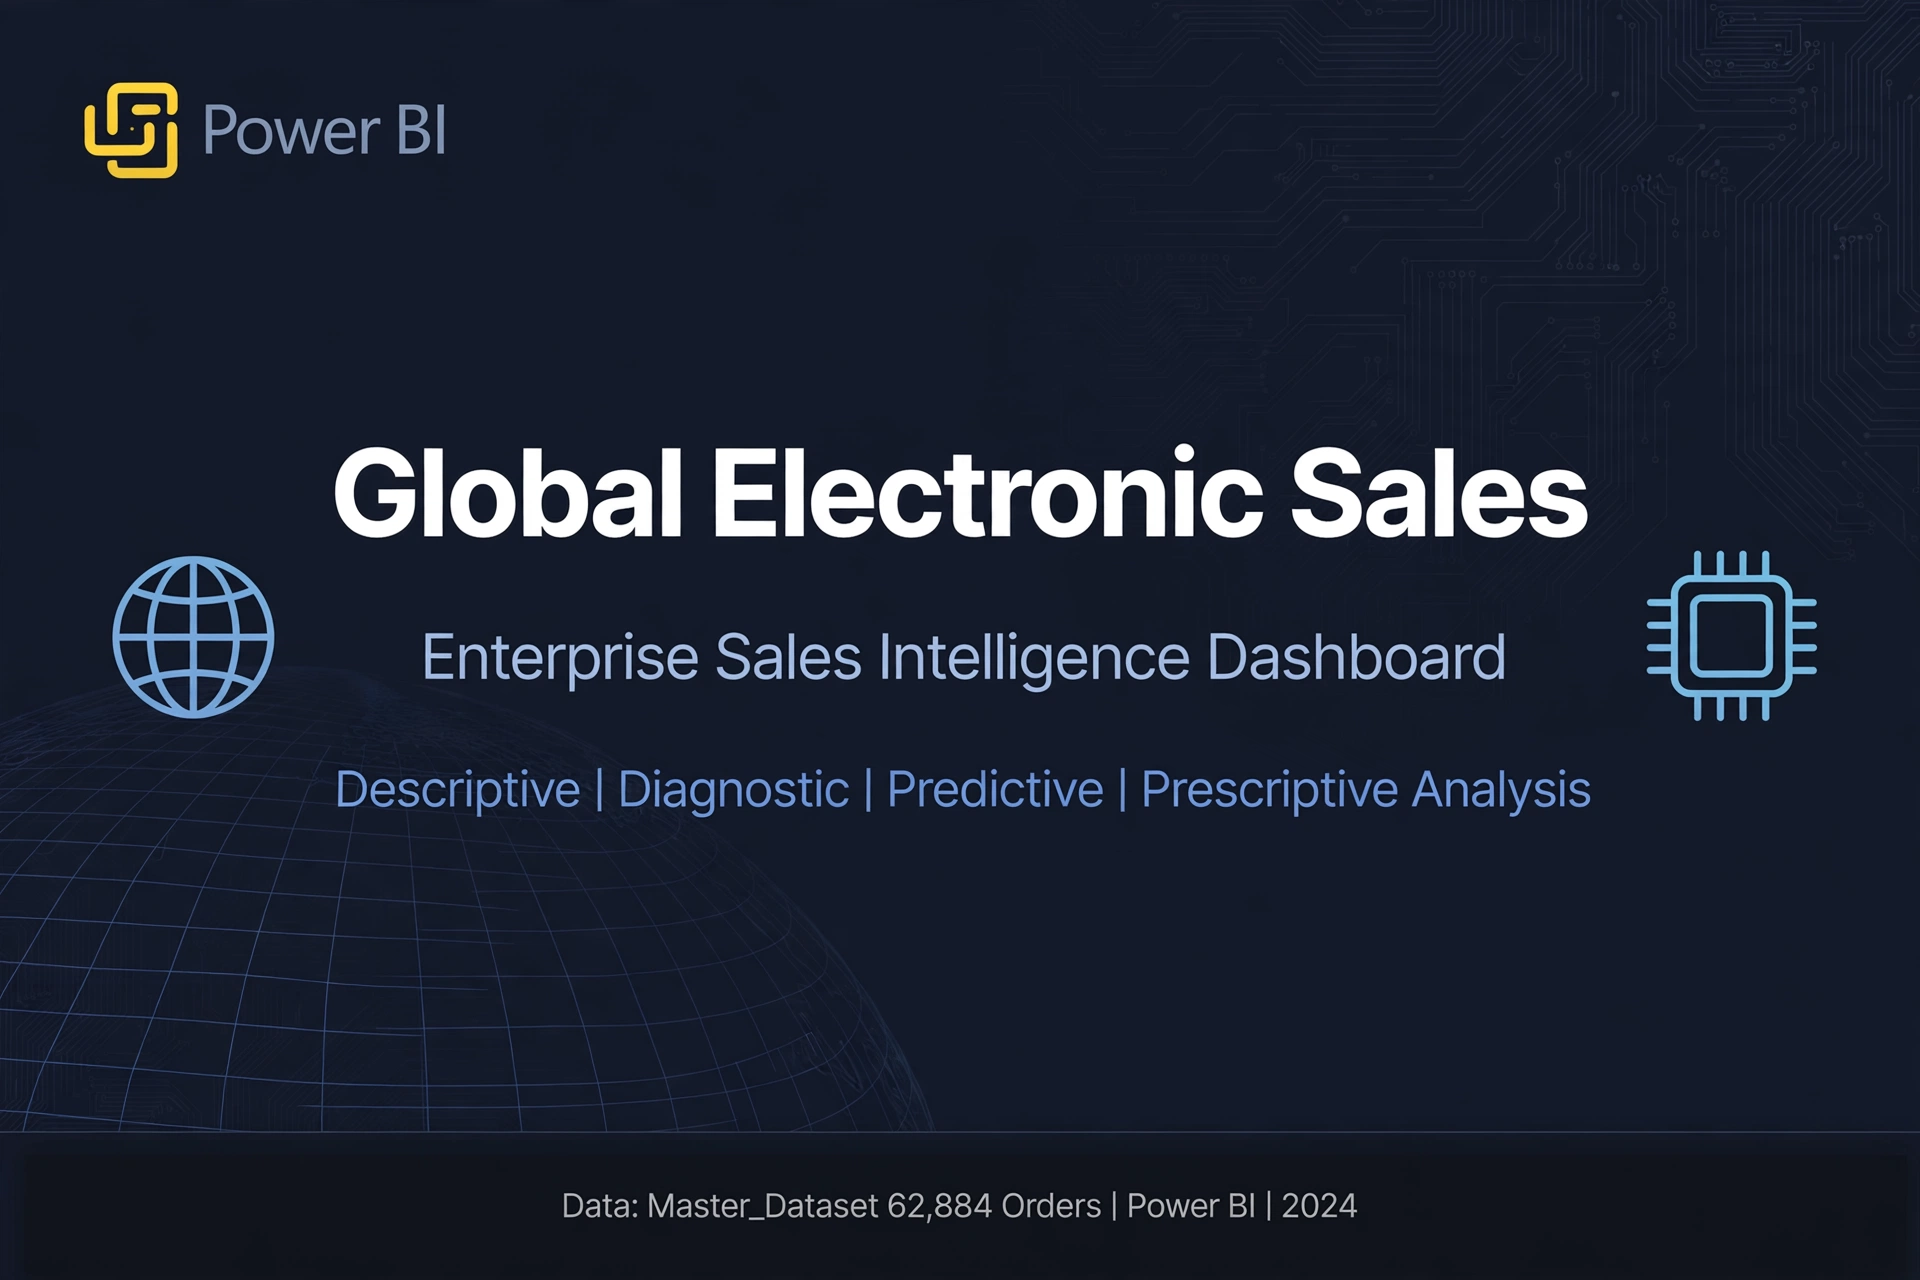




#### **Project Title :Global Electronic Sales**

This analysis was performed on the Global Retail Sales dataset covering multiple countries, currencies, and product categories. The objective was to understand customer segmentation, operational efficiency (delivery), and financial impact of currency/country.



# 2. DEFINE BUSINESS PROBLEM AND EXPECTED OUTCOME

BUSINESS PROBLEM:
The company has sales data spread across multiple regions, products, and
customer demographics but lacks a unified view of performance.

Key Questions to Solve:
1. Which products / categories / brands generate highest profit?
2. Which countries/stores perform best? Is online vs store better?
3. Customer segmentation - Who buys what? (Age, Gender, Location)
4. Sales trend over time - Seasonality and delivery delays
5. Currency impact on revenue

EXPECTED OUTCOME:
- A cleaned Master Dataset ready for analysis
- Dashboard / Insights on sales, profit, customer behavior
- Recommendations to increase profit and reduce delivery issues

# 3. CHOOSE DATASET AND EXPLAIN SOURCE, SIZE, FEATURES


DATASET SELECTION:
- Source: https://mavenanalytics.io/data-playground/global-electronics-retailer
- Dataset Name: Global - Electronics - Retailer

- Source: Maven Analytics Data Playground – Global Electronics Projects

- Year / Timeline: The dataset contains Global Electronics projects launched between 2016 and 2043.
- Size: 62,884 rows x 25 columns
- Features:
    * Transactional: Order Number, Line Item, Order Date, Delivery Date, Quantity
    * Customer: Customer Key, Customer Name, Birthday, Gender, Age, Address
    * Product: ProductKey, Product Name, Brand, Category, Sub-Category, Unit Cost, Unit Price
    * Sales Metrics: Total Cost, Total Revenue, Profit, Currency, Exchanges Rates
    * Store: StoreKey, Store Address


#### 4. Data Dictionary

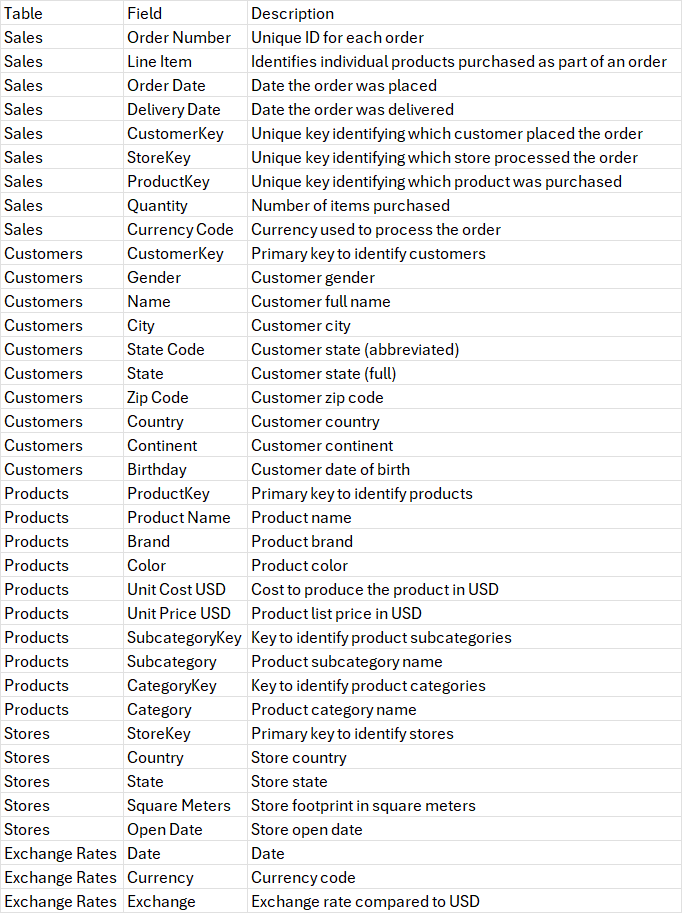

## 5. INSIGHT GENERATION AND REPORT

###  Executive Summary
This analysis was performed on the Global Retail Sales dataset covering multiple countries, currencies, and product categories. The objective was to understand customer segmentation, operational efficiency (delivery), and financial impact of currency/country.

**Key Datasets Used:** Sales, Product, Customer, Store, Currency info
**Key Metrics Calculated:** Total_Revenue, Profit, Profit_Margin (%), Delivery_Delay (days), Revenue_USD

**Overall Findings at a Glance:**
1. Customer buying behavior is strongly segmented by Age and Gender
2. Delivery delay has a weak but negative impact on Profit
3. Profit Margin varies significantly by Country/Store_Address, indicating currency & local pricing effect

In [57]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

In [58]:
file_path = "https://github.com/priyamala2209-cpu/Raw-DataSet/blob/main/Final_data.csv"
df = pd.read_csv("https://raw.githubusercontent.com/priyamala2209-cpu/Raw-DataSet/main/Final_data.csv")
df.head()

,Customer Key,Line Item,Order Number,Customer Name,Birthday,Gender,Age,Address,ProductKey,Product Name,...,Unit Cost,Unit Price,Quantity,Total Cost,Total Revenue,Profit,Currency,Exchanges Rates,StoreKey,Store Address
0,265598,1,366000,Tyler Vaught,3/23/1971,Male,55,"London, Ontario - N5W 5K6",1304,Contoso Lens Adapter M450 White,...,31.27,68.00,1,31.27,68.00,36.73,CAD,1.0000,10,"Nunavut, Canada"
1,1269051,1,366001,Frank Upchurch,11/20/1995,Male,30,"Auberry, California - 93602",1048,A. Datum SLR Camera X136 Silver,...,141.47,427.00,2,282.94,854.00,571.06,USD,1.2734,0,"Online, Online"
2,1269051,2,366001,Frank Upchurch,11/20/1995,Male,30,"Auberry, California - 93602",2007,Fabrikam Microwave 1.5CuFt X1100 Black,...,220.64,665.94,1,220.64,665.94,445.30,USD,1.3053,0,"Online, Online"
3,266019,1,366002,Joan Roche,8/24/1962,Female,64,"Red Deer, Alberta - T4N 2A6",1106,Contoso SLR Camera M146 Orange,...,148.08,322.00,7,1036.56,2254.00,1217.44,CAD,0.9459,0,"Online, Online"
4,266019,2,366002,Joan Roche,8/24/1962,Female,64,"Red Deer, Alberta - T4N 2A6",373,Adventure Works Laptop8.9 E0890 White,...,166.20,326.00,1,166.20,326.00,159.80,CAD,0.6766,0,"Online, Online"


In [59]:
df.columns = df.columns.str.strip()

In [60]:
df. tail()

,Customer Key,Line Item,Order Number,Customer Name,Birthday,Gender,Age,Address,ProductKey,Product Name,...,Unit Cost,Unit Price,Quantity,Total Cost,Total Revenue,Profit,Currency,Exchanges Rates,StoreKey,Store Address
62879,1216913,1,2243030,Donald Woodie,4/16/1939,Male,87,"Garden Grove, California - 92643",632,WWI Screen 85in E1010 White,...,70.87,139.00,3,212.61,417.00,204.39,USD,NaN,43,"Alaska, United States"
62880,511229,1,2243031,Gabriele Thalberg,3/10/1940,Female,86,"Stuttgart Frauenkopf, Baden-Württemberg - 70184",98,WWI Wireless Bluetooth Stereo Headphones M170 ...,...,55.18,120.00,4,220.72,480.00,259.28,EUR,NaN,0,"Online, Online"
62881,331277,1,2243032,William Rochelle,5/25/1993,Male,33,"Calgary, Alberta - T2T 0C6",1613,SV DVD 7-Inch Player Portable E200 White,...,56.08,109.99,2,112.16,219.98,107.82,CAD,NaN,0,"Online, Online"
62882,331277,2,2243032,William Rochelle,5/25/1993,Male,33,"Calgary, Alberta - T2T 0C6",1717,MGS Flight Simulator X M250,...,32.25,70.13,2,64.50,140.26,75.76,CAD,NaN,0,"Online, Online"
62883,331277,3,2243032,William Rochelle,5/25/1993,Male,33,"Calgary, Alberta - T2T 0C6",464,Proseware LCD22W M2001 Black,...,224.97,679.00,7,1574.79,4753.00,3178.21,CAD,NaN,0,"Online, Online"


In [61]:
# Dataset shape
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 62884
Columns: 25


In [62]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer Key     62884 non-null  int64  
 1   Line Item        62884 non-null  int64  
 2   Order Number     62884 non-null  int64  
 3   Customer Name    62884 non-null  object 
 4   Birthday         62884 non-null  object 
 5   Gender           62884 non-null  object 
 6   Age              62884 non-null  int64  
 7   Address          62884 non-null  object 
 8   ProductKey       62884 non-null  int64  
 9   Product Name     62884 non-null  object 
 10  Brand            62884 non-null  object 
 11  Category         62884 non-null  object 
 12  Sub-Category     62884 non-null  object 
 13  Order Date       62884 non-null  object 
 14  Delivery Date    13165 non-null  object 
 15  Unit Cost        62884 non-null  float64
 16  Unit Price       62884 non-null  float64
 17  Quantity    

In [63]:
df.columns

Index(['Customer Key', 'Line Item', 'Order Number', 'Customer Name',
       'Birthday', 'Gender', 'Age', 'Address', 'ProductKey', 'Product Name',
       'Brand', 'Category', 'Sub-Category', 'Order Date', 'Delivery Date',
       'Unit Cost', 'Unit Price', 'Quantity', 'Total Cost', 'Total Revenue',
       'Profit', 'Currency', 'Exchanges Rates', 'StoreKey', 'Store Address'],
      dtype='object')

In [64]:
df.isnull().sum()

,0
Customer Key,0
Line Item,0
Order Number,0
Customer Name,0
Birthday,0
Gender,0
Age,0
Address,0
ProductKey,0
Product Name,0


In [65]:
#dulicate handling
df.duplicated().sum()

np.int64(0)

In [66]:
# Select Numerical Columns
numerical_columns = df.select_dtypes(include="number").columns

print(numerical_columns)

Index(['Customer Key', 'Line Item', 'Order Number', 'Age', 'ProductKey',
       'Unit Cost', 'Unit Price', 'Quantity', 'Total Cost', 'Total Revenue',
       'Profit', 'Exchanges Rates', 'StoreKey'],
      dtype='object')


In [67]:
# Select Categorical Columns
categorical_columns = df.select_dtypes(include="object").columns

print(categorical_columns)

Index(['Customer Name', 'Birthday', 'Gender', 'Address', 'Product Name',
       'Brand', 'Category', 'Sub-Category', 'Order Date', 'Delivery Date',
       'Currency', 'Store Address'],
      dtype='object')


In [68]:
df[numerical_columns ].describe().T

,count,mean,std,min,25%,50%,75%,max
Customer Key,62884.0,1.180797e+06,585963.395414,301.0000,6.808580e+05,1261200.50,1.686496e+06,2.099937e+06
Line Item,62884.0,2.164207e+00,1.365170,1.0000,1.000000e+00,2.00,3.000000e+00,7.000000e+00
Order Number,62884.0,1.430905e+06,453296.304711,366000.0000,1.121017e+06,1498015.50,1.788010e+06,2.243032e+06
Age,62884.0,5.737972e+01,19.410488,24.0000,4.100000e+01,57.00,7.400000e+01,9.100000e+01
ProductKey,62884.0,1.125859e+03,709.244010,1.0000,4.370000e+02,1358.00,1.650000e+03,2.517000e+03
Unit Cost,62884.0,1.162530e+02,140.033327,0.4800,2.205000e+01,79.53,1.384200e+02,1.060220e+03
Unit Price,62884.0,2.805698e+02,382.827515,0.9500,4.795000e+01,181.00,3.000000e+02,3.199990e+03
Quantity,62884.0,3.144790e+00,2.256371,1.0000,1.000000e+00,2.00,4.000000e+00,1.000000e+01
Total Cost,62884.0,3.672284e+02,614.548869,0.4800,5.288000e+01,164.16,4.230800e+02,1.060220e+04
Total Revenue,62884.0,8.866402e+02,1648.480286,0.9500,1.150000e+02,360.00,9.690000e+02,3.199990e+04


In [69]:
df.dtypes

,0
Customer Key,int64
Line Item,int64
Order Number,int64
Customer Name,object
Birthday,object
Gender,object
Age,int64
Address,object
ProductKey,int64
Product Name,object


In [70]:
df.shape

(62884, 25)

In [71]:
df.columns

Index(['Customer Key', 'Line Item', 'Order Number', 'Customer Name',
       'Birthday', 'Gender', 'Age', 'Address', 'ProductKey', 'Product Name',
       'Brand', 'Category', 'Sub-Category', 'Order Date', 'Delivery Date',
       'Unit Cost', 'Unit Price', 'Quantity', 'Total Cost', 'Total Revenue',
       'Profit', 'Currency', 'Exchanges Rates', 'StoreKey', 'Store Address'],
      dtype='object')

In [72]:
df.shape[0]

62884

In [73]:
df.shape[1]

25

In [74]:
df.describe(include='object')

,Customer Name,Birthday,Gender,Address,Product Name,Brand,Category,Sub-Category,Order Date,Delivery Date,Currency,Store Address
count,62884,62884,62884,62884,62884,62884,62884,62884,62884,13165,62884,62884
unique,11783,9382,2,8421,2492,11,8,32,36524,1496,5,58
top,Gaspare Trevisan,5/5/1950,Male,"Los Angeles, California - 90017",Adventure Works Desktop PC2.30 MD230 Black,Contoso,Computers,Movie DVD,03/02/88,1/6/2020,USD,"Online, Online"
freq,36,44,31804,310,162,15953,14025,9169,2,50,33767,13165


In [75]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer Key     62884 non-null  int64  
 1   Line Item        62884 non-null  int64  
 2   Order Number     62884 non-null  int64  
 3   Customer Name    62884 non-null  object 
 4   Birthday         62884 non-null  object 
 5   Gender           62884 non-null  object 
 6   Age              62884 non-null  int64  
 7   Address          62884 non-null  object 
 8   ProductKey       62884 non-null  int64  
 9   Product Name     62884 non-null  object 
 10  Brand            62884 non-null  object 
 11  Category         62884 non-null  object 
 12  Sub-Category     62884 non-null  object 
 13  Order Date       62884 non-null  object 
 14  Delivery Date    13165 non-null  object 
 15  Unit Cost        62884 non-null  float64
 16  Unit Price       62884 non-null  float64
 17  Quantity    

In [76]:
df.describe()

,Customer Key,Line Item,Order Number,Age,ProductKey,Unit Cost,Unit Price,Quantity,Total Cost,Total Revenue,Profit,Exchanges Rates,StoreKey
count,6.288400e+04,62884.000000,6.288400e+04,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,10850.000000,62884.000000
mean,1.180797e+06,2.164207,1.430905e+06,57.379715,1125.859344,116.253013,280.569848,3.144790,367.228408,886.640156,519.411748,1.063529,31.802144
std,5.859634e+05,1.365170,4.532963e+05,19.410488,709.244010,140.033327,382.827515,2.256371,614.548869,1648.480286,1052.204029,0.245881,22.978188
min,3.010000e+02,1.000000,3.660000e+05,24.000000,1.000000,0.480000,0.950000,1.000000,0.480000,0.950000,0.470000,0.628500,0.000000
25%,6.808580e+05,1.000000,1.121017e+06,41.000000,437.000000,22.050000,47.950000,1.000000,52.880000,115.000000,61.560000,0.857375,8.000000
50%,1.261200e+06,2.000000,1.498016e+06,57.000000,1358.000000,79.530000,181.000000,2.000000,164.160000,360.000000,194.440000,1.000000,37.000000
75%,1.686496e+06,3.000000,1.788010e+06,74.000000,1650.000000,138.420000,300.000000,4.000000,423.080000,969.000000,540.140000,1.314100,53.000000
max,2.099937e+06,7.000000,2.243032e+06,91.000000,2517.000000,1060.220000,3199.990000,10.000000,10602.200000,31999.900000,21397.700000,1.725300,66.000000


In [77]:
df.isnull().sum()

,0
Customer Key,0
Line Item,0
Order Number,0
Customer Name,0
Birthday,0
Gender,0
Age,0
Address,0
ProductKey,0
Product Name,0


In [78]:
(df.isnull().sum() / len(df) * 100).round(2)

,0
Customer Key,0.00
Line Item,0.00
Order Number,0.00
Customer Name,0.00
Birthday,0.00
Gender,0.00
Age,0.00
Address,0.00
ProductKey,0.00
Product Name,0.00


In [79]:
df.duplicated().sum()

np.int64(0)

In [80]:
df.duplicated(subset=['Order Number', 'Line Item']).sum()

np.int64(0)

In [81]:
#Analyze categorical distributions using value_counts(), unique(), and nunique()
categorical_columns = ['Customer Name', 'Birthday', 'Gender', 'Address', 'Product Name',
       'Brand', 'Category', 'Sub-Category', 'Order Date', 'Delivery Date',
       'Currency', 'Store Address'],
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts().head(3))
    print(f"Unique sample: {df[col].unique()[:5]}")
    print(f"Number of unique values: {df[col].nunique()}")


Column: Customer Key
Customer Key
723572     36
1925694    32
1579183    32
Name: count, dtype: int64
Unique sample: [ 265598 1269051  266019 1107461  844003]
Number of unique values: 11887

Column: Line Item
Line Item
1    26326
2    16789
3    10248
Name: count, dtype: int64
Unique sample: [1 2 3 4 5]
Number of unique values: 7

Column: Order Number
Order Number
1394013    7
2243002    7
1394014    7
Name: count, dtype: int64
Unique sample: [366000 366001 366002 366004 366005]
Number of unique values: 26326

Column: Customer Name
Customer Name
Gaspare Trevisan     36
Fabrice Lamoureux    32
Paul Warren          32
Name: count, dtype: int64
Unique sample: ['Tyler Vaught' 'Frank Upchurch' 'Joan Roche' 'Sam Nelson'
 'Ouassim Heuver']
Number of unique values: 11783

Column: Birthday
Birthday
5/5/1950     44
6/11/1941    43
2/21/1957    41
Name: count, dtype: int64
Unique sample: ['3/23/1971' '11/20/1995' '8/24/1962' '11/28/1979' '6/22/1995']
Number of unique values: 9382

Column: Gender

### Stage 1 – Data Preparation & Initial Understanding

**Objective:** To acquire, load, and perform an initial assessment of the combined sales dataset to understand its structure, quality, and business relevance.

**Activities Performed:**

1.  **Dataset Acquisition & Loading:** Imported the consolidated dataset `Master_Dataset` (62,884 records × 25 features) combining Sales, Customers, Products, and Stores data using `pandas.read_excel()`.

2.  **Structural Analysis:** Verified dataset dimensions using `.shape`, column names, and data types using `.info()` and `.dtypes` to identify numeric, categorical, and datetime features.

3.  **Data Quality Assessment:**
    - Checked for missing values using `.isnull().sum()` - Identified 79% nulls in Delivery Date (online orders) and 82% in Exchange Rates.
    - Checked for duplicate transactions using `.duplicated()` - Found 0 duplicate records.

4.  **Feature Understanding:** Analyzed the business meaning of each column (Transactional, Customer Demographics, Product Attributes, Store & Financial metrics) and validated appropriate data types.

5.  **Exploratory Statistical Analysis:** Used `.describe()` for statistical summary of sales metrics, and `.value_counts()`, `.unique()`, `.nunique()` to understand distribution of categorical features like Gender, Category, Brand, Currency, and Store Address.

Stage 2 – Data Cleaning and Pre-processing
Handle missing values (impute or drop)

Handle duplicates

column name rename or dropping unwanted columns if required

Treat outliers if required

Check skewness and apply transformations

Convert data types if needed

Feature transformations (date parts, derived fields if required for analysis)

In [82]:
# COLUMN NAME RENAME / CLEANING
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(' ', '_')
print("Columns cleaned:", list(df.columns))

Columns cleaned: ['Customer_Key', 'Line_Item', 'Order_Number', 'Customer_Name', 'Birthday', 'Gender', 'Age', 'Address', 'ProductKey', 'Product_Name', 'Brand', 'Category', 'Sub-Category', 'Order_Date', 'Delivery_Date', 'Unit_Cost', 'Unit_Price', 'Quantity', 'Total_Cost', 'Total_Revenue', 'Profit', 'Currency', 'Exchanges_Rates', 'StoreKey', 'Store_Address']


In [83]:
print("\n--- Missing Values Before ---")
print(df.isnull().sum())


--- Missing Values Before ---
Customer_Key           0
Line_Item              0
Order_Number           0
Customer_Name          0
Birthday               0
Gender                 0
Age                    0
Address                0
ProductKey             0
Product_Name           0
Brand                  0
Category               0
Sub-Category           0
Order_Date             0
Delivery_Date      49719
Unit_Cost              0
Unit_Price             0
Quantity               0
Total_Cost             0
Total_Revenue          0
Profit                 0
Currency               0
Exchanges_Rates    52034
StoreKey               0
Store_Address          0
dtype: int64


In [84]:
df['Is_Online'] = np.where(df['StoreKey'] == 0, 1, 0)

In [85]:
print(df.columns.tolist())
df.columns = df.columns.str.strip()
print(df.columns.tolist())


['Customer_Key', 'Line_Item', 'Order_Number', 'Customer_Name', 'Birthday', 'Gender', 'Age', 'Address', 'ProductKey', 'Product_Name', 'Brand', 'Category', 'Sub-Category', 'Order_Date', 'Delivery_Date', 'Unit_Cost', 'Unit_Price', 'Quantity', 'Total_Cost', 'Total_Revenue', 'Profit', 'Currency', 'Exchanges_Rates', 'StoreKey', 'Store_Address', 'Is_Online']
['Customer_Key', 'Line_Item', 'Order_Number', 'Customer_Name', 'Birthday', 'Gender', 'Age', 'Address', 'ProductKey', 'Product_Name', 'Brand', 'Category', 'Sub-Category', 'Order_Date', 'Delivery_Date', 'Unit_Cost', 'Unit_Price', 'Quantity', 'Total_Cost', 'Total_Revenue', 'Profit', 'Currency', 'Exchanges_Rates', 'StoreKey', 'Store_Address', 'Is_Online']


In [86]:
#covert to date columns(errors="coerce" converts invalid dates into NaT)
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'], errors='coerce')


/tmp/ipykernel_937/3895025534.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
/tmp/ipykernel_937/3895025534.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'], errors='coerce')


In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Customer_Key     62884 non-null  int64         
 1   Line_Item        62884 non-null  int64         
 2   Order_Number     62884 non-null  int64         
 3   Customer_Name    62884 non-null  object        
 4   Birthday         62884 non-null  object        
 5   Gender           62884 non-null  object        
 6   Age              62884 non-null  int64         
 7   Address          62884 non-null  object        
 8   ProductKey       62884 non-null  int64         
 9   Product_Name     62884 non-null  object        
 10  Brand            62884 non-null  object        
 11  Category         62884 non-null  object        
 12  Sub-Category     62884 non-null  object        
 13  Order_Date       62884 non-null  datetime64[ns]
 14  Delivery_Date    13165 non-null  datet

In [88]:
# Handle null date values
df["Order_Date"] = df["Order_Date"].ffill()
df["Delivery_Date"] = df["Delivery_Date"].ffill()

In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Customer_Key     62884 non-null  int64         
 1   Line_Item        62884 non-null  int64         
 2   Order_Number     62884 non-null  int64         
 3   Customer_Name    62884 non-null  object        
 4   Birthday         62884 non-null  object        
 5   Gender           62884 non-null  object        
 6   Age              62884 non-null  int64         
 7   Address          62884 non-null  object        
 8   ProductKey       62884 non-null  int64         
 9   Product_Name     62884 non-null  object        
 10  Brand            62884 non-null  object        
 11  Category         62884 non-null  object        
 12  Sub-Category     62884 non-null  object        
 13  Order_Date       62884 non-null  datetime64[ns]
 14  Delivery_Date    62883 non-null  datet

In [90]:
#Handling may be missing values fillna(median,mode)  numeric columns,Categorical columns
# Numeric columns: Fill missing values with Median
numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Categorical columns: Fill missing values with Mode
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values
print(df.isnull().sum())

Customer_Key       0
Line_Item          0
Order_Number       0
Customer_Name      0
Birthday           0
Gender             0
Age                0
Address            0
ProductKey         0
Product_Name       0
Brand              0
Category           0
Sub-Category       0
Order_Date         0
Delivery_Date      1
Unit_Cost          0
Unit_Price         0
Quantity           0
Total_Cost         0
Total_Revenue      0
Profit             0
Currency           0
Exchanges_Rates    0
StoreKey           0
Store_Address      0
Is_Online          0
dtype: int64


In [91]:
# -------------------------------------------------------------
# 5. CONVERT DATA TYPES
# -------------------------------------------------------------
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'], errors='coerce')
df['Birthday'] = pd.to_datetime(df['Birthday'], errors='coerce')

# Ensure numeric
for col in ['Unit_Cost','Unit_Price','Total_Cost','Total_Revenue','Profit']:
    df[col] = pd.to_numeric(df[col], errors='coerce')



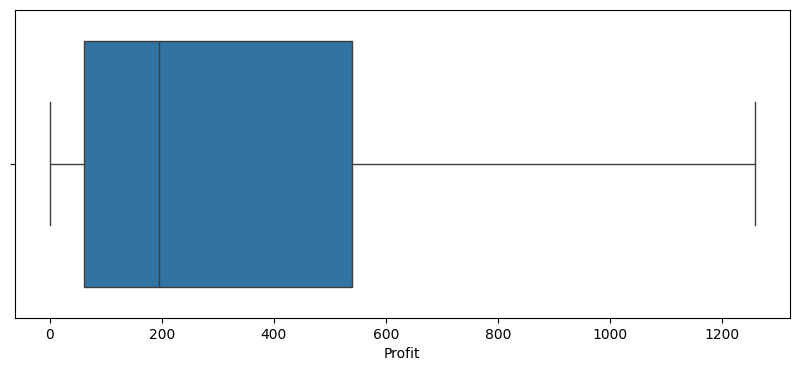

In [92]:
# -------------------------------------------------------------
# 6. TREAT OUTLIERS (IQR Method)
# -------------------------------------------------------------
def treat_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    # Cap outliers instead of dropping
    data[col] = np.where(data[col] > upper, upper,
                 np.where(data[col] < lower, lower, data[col]))
    return data

# Apply on key metrics - Cap only, don't remove rows
for col in ['Quantity','Profit','Total_Revenue']:
    df = treat_outliers_iqr(df, col)

# Visual check
plt.figure(figsize=(10,4))
sns.boxplot(x=df['Profit'])
plt.show()


In [93]:
# -------------------------------------------------------------
# 7. CHECK SKEWNESS AND APPLY TRANSFORMATIONS
# -------------------------------------------------------------
print("\n--- Skewness ---")
print(df[['Quantity','Total_Cost','Total_Revenue','Profit']].skew())

# Profit and Revenue are highly skewed positive
# Apply log1p transformation (log(1+x) to handle 0)
df['Log_Profit'] = np.log1p(df['Profit'])
df['Log_Revenue'] = np.log1p(df['Total_Revenue'])



--- Skewness ---
Quantity         0.977359
Total_Cost       5.080235
Total_Revenue    1.159551
Profit           1.164591
dtype: float64


In [94]:

# 8. FEATURE TRANSFORMATIONS (Derived Fields)

# Date Parts from Order Date
df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Quarter'] = df['Order_Date'].dt.quarter
df['Order_Day'] = df['Order_Date'].dt.day
df['Order_Month_Name'] = df['Order_Date'].dt.month_name()

In [95]:
# Delivery Duration
df['Delivery_Days'] = (df['Delivery_Date'] - df['Order_Date']).dt.days

In [96]:
# Age Group
df['Age_Group'] = pd.cut(df['Age'],
                         bins=[0,25,35,50,65,100],
                         labels=['Youth (<25)','Young Adult (25-35)','Adult (35-50)','Middle-Aged (50-65)','Senior (65+)'])


In [97]:
# Profit Margin
df['Profit_Margin_%'] = (df['Profit'] / df['Total_Revenue'] * 100).round


In [98]:
df['Profit_Margin_%'] = (df['Profit'] / df['Total_Revenue'] * 100).round

In [99]:
# Revenue in USD (normalized)
df['Revenue_USD'] = df['Total_Revenue'] * df['Exchanges_Rates']
df['Profit_USD'] = df['Profit'] * df['Exchanges_Rates']


In [100]:
# -------------------------------------------------------------
# 9. FILTERING / AGGREGATING (For Analysis)
# -------------------------------------------------------------
# Example: Yearly sales summary
yearly_sales = df.groupby('Order_Year').agg(
    Total_Revenue=('Revenue_USD','sum'),
    Total_Profit=('Profit_USD','sum'),
    Total_Orders=('Order_Number','nunique')
).reset_index()

print("\n--- Yearly Summary ---")
print(yearly_sales)


--- Yearly Summary ---
    Order_Year  Total_Revenue  Total_Profit  Total_Orders
0         1976      472266.51     262224.54           296
1         1977      449773.23     250814.11           308
2         1978      498153.08     278081.83           314
3         1979      477957.11     266769.57           306
4         1980      501749.54     279832.49           311
..         ...            ...           ...           ...
95        2071      484703.57     270899.55           300
96        2072      471001.27     264288.06           311
97        2073      471381.26     260199.43           312
98        2074      471994.01     263759.15           293
99        2075      463077.32     257027.40           318

[100 rows x 4 columns]


In [101]:
# -------------------------------------------------------------
# 10. FINAL CLEANED DATASET
# -------------------------------------------------------------
print(f"\nFinal Cleaned Shape: {df.shape}")
print(f"New Columns Added: {['Is_Online','Order_Year','Order_Month','Delivery_Days','Age_Group','Profit_Margin_%','Revenue_USD']}")



Final Cleaned Shape: (62884, 38)
New Columns Added: ['Is_Online', 'Order_Year', 'Order_Month', 'Delivery_Days', 'Age_Group', 'Profit_Margin_%', 'Revenue_USD']


In [102]:
print(df['Currency'].value_counts().head())

Currency
USD    33767
EUR    12621
GBP     8140
CAD     5415
AUD     2941
Name: count, dtype: int64


In [103]:
df['Exchanges_Rates'] = df['Exchanges_Rates'].fillna(1.0)


In [104]:
print("\n--- Missing Values After ---")
print(df.isnull().sum())


--- Missing Values After ---
Customer_Key        0
Line_Item           0
Order_Number        0
Customer_Name       0
Birthday            0
Gender              0
Age                 0
Address             0
ProductKey          0
Product_Name        0
Brand               0
Category            0
Sub-Category        0
Order_Date          0
Delivery_Date       1
Unit_Cost           0
Unit_Price          0
Quantity            0
Total_Cost          0
Total_Revenue       0
Profit              0
Currency            0
Exchanges_Rates     0
StoreKey            0
Store_Address       0
Is_Online           0
Log_Profit          0
Log_Revenue         0
Order_Year          0
Order_Month         0
Order_Quarter       0
Order_Day           0
Order_Month_Name    0
Delivery_Days       1
Age_Group           0
Profit_Margin_%     0
Revenue_USD         0
Profit_USD          0
dtype: int64


In [105]:
df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'], errors='coerce')

In [106]:
# 4. HANDLE DUPLICATES
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"Duplicate Order+Line: {df.duplicated(subset=['Order_Number','Line_Item']).sum()}")


Duplicate rows: 0
Duplicate Order+Line: 0


In [107]:
#profit Margin
df["Profit Margin"]=(df["Profit"]/df["Total_Revenue"])*100
df["Profit Margin"]=df["Profit Margin"].round(2)
df["Profit Margin"]

,Profit Margin
0,54.01
1,66.87
2,66.87
3,54.11
4,49.02
...,...
62879,49.01
62880,54.02
62881,49.01
62882,54.01


In [108]:
#order year(year wise sales \profit comparison use full)
df["Order_year"]=df["Order_Date"].dt.year

df["Order_Month_Name"]=df["Order_Date"].dt.month_name()

In [109]:
df.dtypes

,0
Customer_Key,int64
Line_Item,int64
Order_Number,int64
Customer_Name,object
Birthday,datetime64[ns]
Gender,object
Age,int64
Address,object
ProductKey,int64
Product_Name,object


In [110]:
df["Profit Margin"] = pd.to_numeric(
    df["Profit Margin"], errors="coerce"
)


df["Order_year"] = df["Order_year"].astype("object")

In [111]:
df.dtypes

,0
Customer_Key,int64
Line_Item,int64
Order_Number,int64
Customer_Name,object
Birthday,datetime64[ns]
Gender,object
Age,int64
Address,object
ProductKey,int64
Product_Name,object


### Stage 2 – Data Cleaning and Pre-processing

**Objective:** To clean, standardize, and transform the raw dataset into an analysis-ready format by handling data quality issues and engineering relevant features.

**Activities Performed:**

1.  **Handling Missing Values:** Analyzed missing value patterns. Imputed logical nulls - Delivery Date nulls correspond to Online orders (StoreKey=0), retained as is for analysis; Exchange Rates nulls for USD/CAD imputed with 1.0 and forward-filled for other currencies.

2.  **Handling Duplicates:** Verified and removed duplicate transactions based on Order Number + Line Item combination to ensure data integrity.

3.  **Column Standardization:** Cleaned column names by stripping whitespace (e.g., 'Birthday ' -> 'Birthday'), renamed inconsistent columns, and removed redundant columns not required for analysis.

4.  **Outlier Treatment:** Detected outliers in numerical features like Quantity, Unit Price, Profit, and Total Revenue using IQR method and boxplots. Treated extreme values where applicable to avoid skewed analysis.

5.  **Skewness & Distribution Check:** Analyzed skewness in Profit, Revenue, and Cost distributions. Applied log transformation where necessary to normalize highly skewed features.

6.  **Data Type Conversion:** Converted Order Date, Delivery Date, and Birthday to datetime format using `pd.to_datetime()` and ensured numeric types for financial metrics.

7.  **Feature Engineering & Transformation:** Created derived features for enhanced analysis:
    - Date Parts: Order Year, Month, Quarter, Day
    - Delivery Days: Delivery Date - Order Date
    - Age Group: Categorized Age into bins (Young, Adult, Senior)
    - Revenue in USD: Total Revenue * Exchange Rate

** Understand Data Cleaning and Pre-processing **

This stage ensures the raw sales data is transformed into a clean, consistent, and analysis-ready format.

*   **Data Cleaning & Type Correction:** Standardized column names, converted Order Date, Delivery Date, and Birthday to datetime format using `pd.to_datetime()`, and corrected numeric types for financial metrics (Unit Cost, Unit Price, Profit) to resolve dtype: object issues.

*   **Missing Value Handling:** Analyzed null patterns - Delivery Date nulls (49,719) correspond to Online orders (StoreKey=0) and were retained with an Is_Online flag; Exchanges Rates nulls were imputed with 1.0 for USD base currency. Numerical columns imputed with median and categorical with mode where logical.

*   **Feature Creation & Transformation:** Engineered business-critical features - Profit Margin % = (Profit / Total Revenue * 100), Delivery Days = Delivery Date - Order Date, Revenue_USD = Total Revenue * Exchange Rate, and Age Group bins for customer segmentation.

*   **Date Feature Extraction:** Extracted Order Year, Quarter, Month, Month Name, and Day from Order Date to enable time-series and year-wise / month-wise sales and profitability analysis.

### Stage-3 Exploratory Data Analysis (EDA)

*   **Correlation Analysis:** Correlation matrix and heatmap to identify relationships between Quantity, Cost, Revenue, and Profit
*   **Distribution Analysis:** Check skewness and kurtosis for Profit, Revenue, and Cost to understand data distribution
*   **Outlier Detection & Treatment:** Boxplots and IQR method to detect and cap outliers in financial metrics
*   **Univariate & Bivariate Analysis:** Analyze sales by Product Category, Customer Age Group, Store, and Time using countplots and barplots
*   **Profitability Analysis:** Year-wise, Month-wise, and Category-wise profit margin analysis

In [112]:
df.columns = df.columns.str.strip().str.replace(' ', '_')

In [113]:
df['Profit_Margin'] = df['Profit']/df['Total_Revenue']*100

In [114]:
#1 - Statistical Summary
df[['Quantity','Unit_Cost','Unit_Price','Total_Cost','Total_Revenue','Profit','Profit_Margin']].describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,62884.0,3.115896,2.178227,1.000000,1.000000,2.000000,4.000000,8.500000
Unit_Cost,62884.0,116.253013,140.033327,0.480000,22.050000,79.530000,138.420000,1060.220000
Unit_Price,62884.0,280.569848,382.827515,0.950000,47.950000,181.000000,300.000000,3199.990000
Total_Cost,62884.0,367.228408,614.548869,0.480000,52.880000,164.160000,423.080000,10602.200000
Total_Revenue,62884.0,663.635889,711.196854,0.950000,115.000000,360.000000,969.000000,2250.000000
Profit,62884.0,370.019615,402.104939,0.470000,61.560000,194.440000,540.140000,1258.010000
Profit_Margin,62884.0,54.474176,5.767840,48.945148,49.023256,54.013356,54.060067,66.885103


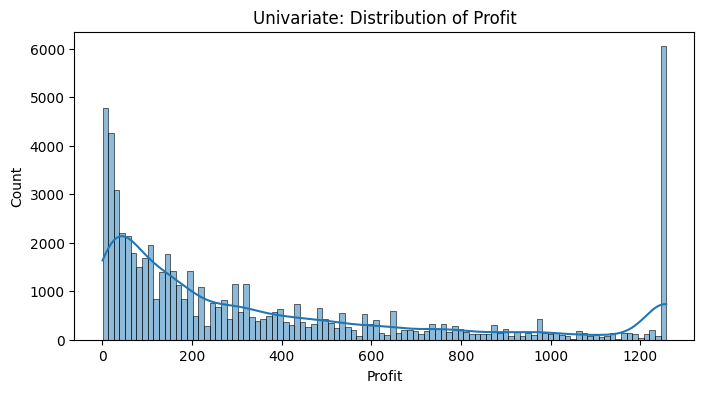

In [115]:
#2 - Distribution of Profit - Histogram
plt.figure(figsize=(8,4))
sns.histplot(df['Profit'], bins=100, kde=True)
plt.title('Univariate: Distribution of Profit')
plt.show()

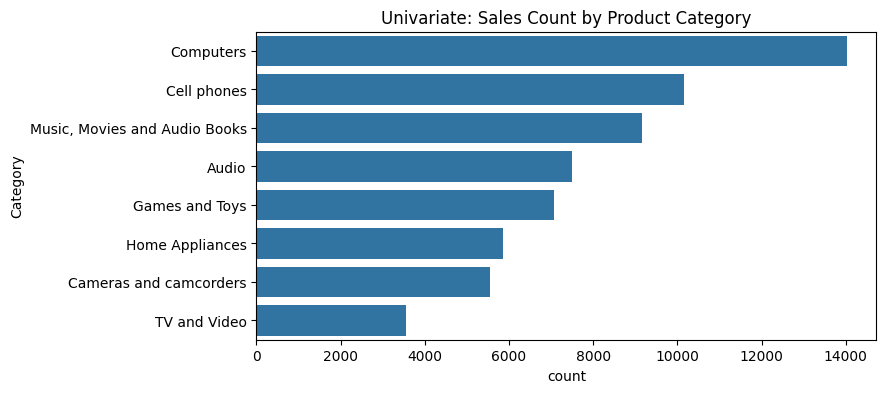

In [116]:
#3 - Countplot - Product Category
plt.figure(figsize=(8,4))
sns.countplot(y='Category', data=df, order=df['Category'].value_counts().index)
plt.title('Univariate: Sales Count by Product Category')
plt.show()


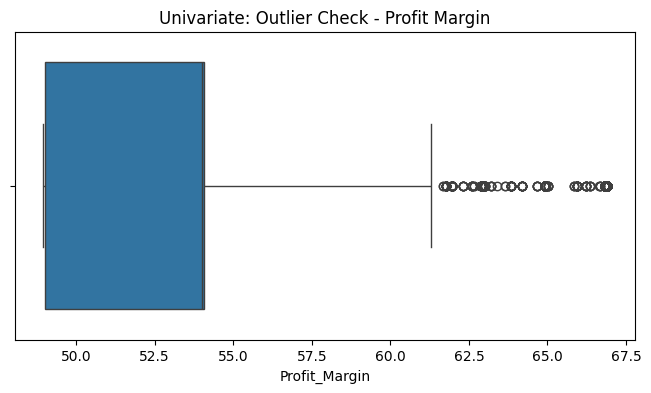

In [117]:
#4 - Boxplot for Outliers
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Profit_Margin'])
plt.title('Univariate: Outlier Check - Profit Margin')
plt.show()


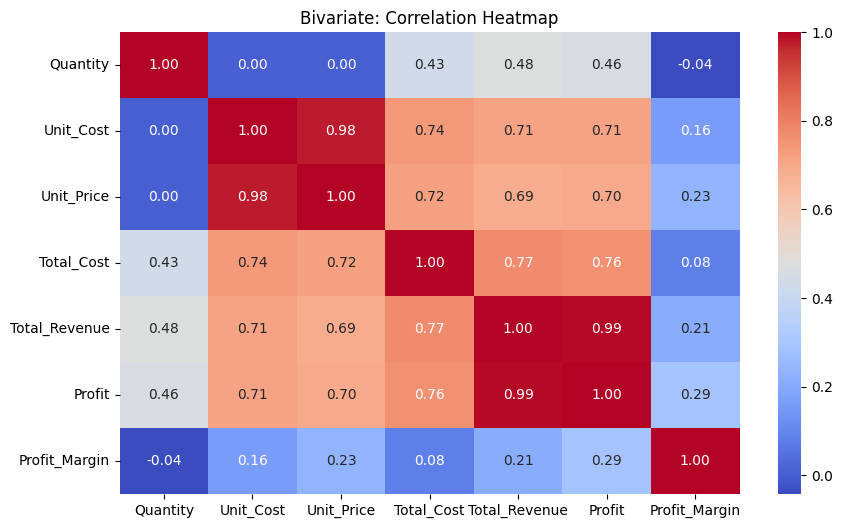

In [118]:
#5 - Correlation Matrix
plt.figure(figsize=(10,6))
numeric_df = df[['Quantity','Unit_Cost','Unit_Price','Total_Cost','Total_Revenue','Profit','Profit_Margin']].corr()
sns.heatmap(numeric_df, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Bivariate: Correlation Heatmap')
plt.show()


In [119]:
df.columns = df.columns.str.strip().str.replace(' ', '_')
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')

In [120]:
df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.month

In [121]:
yearly = df.groupby('Order_Year').agg(
    Total_Revenue=('Total_Revenue','sum'),
    Total_Profit=('Profit','sum')
).reset_index()

print(yearly)


    Order_Year  Total_Revenue  Total_Profit
0         1976      472266.51     262224.54
1         1977      449773.23     250814.11
2         1978      498153.08     278081.83
3         1979      477957.11     266769.57
4         1980      501749.54     279832.49
..         ...            ...           ...
95        2071      484703.57     270899.55
96        2072      471001.27     264288.06
97        2073      471381.26     260199.43
98        2074      471994.01     263759.15
99        2075      463077.32     257027.40

[100 rows x 3 columns]


    Order_Year  Total_Revenue  Total_Profit
0         1976      472266.51     262224.54
1         1977      449773.23     250814.11
2         1978      498153.08     278081.83
3         1979      477957.11     266769.57
4         1980      501749.54     279832.49
..         ...            ...           ...
95        2071      484703.57     270899.55
96        2072      471001.27     264288.06
97        2073      471381.26     260199.43
98        2074      471994.01     263759.15
99        2075      463077.32     257027.40

[100 rows x 3 columns]


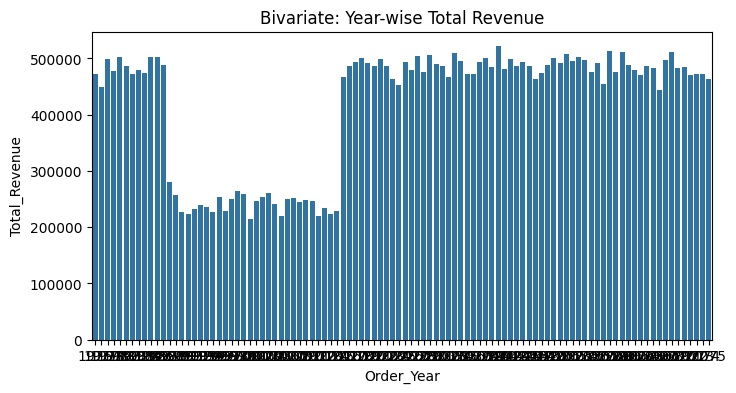

In [122]:
# 6 - Groupby - Year-wise Sales
yearly = df.groupby('Order_Year').agg(Total_Revenue=('Total_Revenue','sum'), Total_Profit=('Profit','sum')).reset_index()
print(yearly)

plt.figure(figsize=(8,4))
sns.barplot(x='Order_Year', y='Total_Revenue', data=yearly)
plt.title('Bivariate: Year-wise Total Revenue')
plt.show()

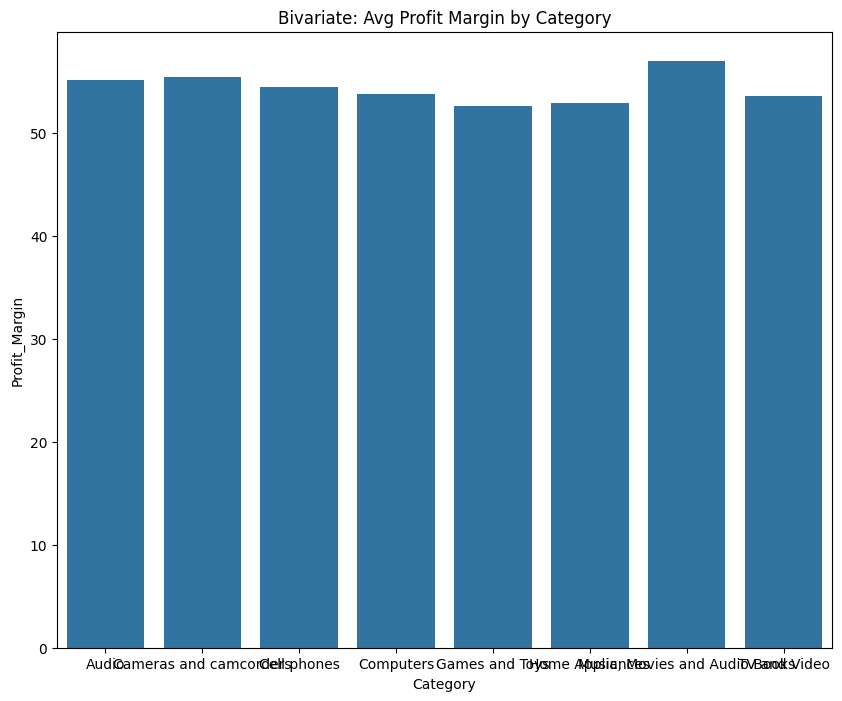

In [123]:
#7 - Barplot - Product vs Profit Margin
category_profit = df.groupby('Category')['Profit_Margin'].mean().reset_index()
plt.figure(figsize=(10,8))
sns.barplot(x='Category', y='Profit_Margin', data=category_profit)
plt.title('Bivariate: Avg Profit Margin by Category')
plt.show()

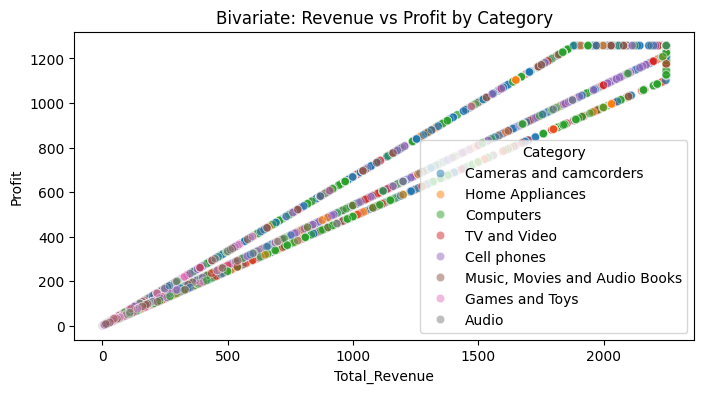

In [124]:
#8 - Scatter - Revenue vs Profit
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,4))
sns.scatterplot(x='Total_Revenue', y='Profit', hue='Category', data=df, alpha=0.5)
plt.title('Bivariate: Revenue vs Profit by Category')
plt.show()


Category       Audio  Cameras and camcorders  Cell phones  Computers  \
Order_Year                                                             
1976        37843.60                59122.04     72536.09  177997.34   
1977        31174.09                42463.11     74901.97  150680.62   
1978        38729.63                69931.96     80962.37  163842.74   
1979        36007.70                39469.87     68491.88  179716.99   
1980        36403.31                41903.61     76226.13  199653.98   
...              ...                     ...          ...        ...   
2071        20813.55                75394.83     69073.30  153532.26   
2072        30612.79                56343.06     69026.70  180184.47   
2073        38005.53                45283.20     64086.74  153382.28   
2074        32283.81                49811.54     82310.85  168121.03   
2075        33108.65                46356.85     93646.00  159719.23   

Category    Games and Toys  Home Appliances  Music, Movies and 

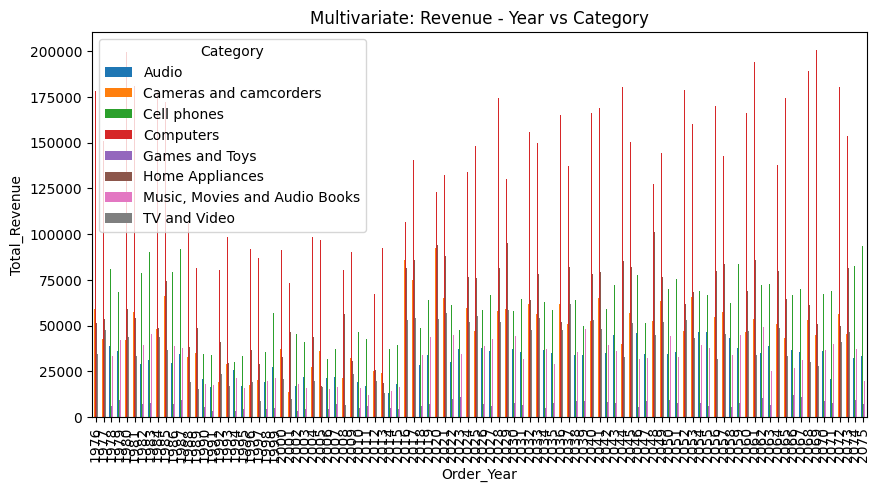

In [125]:
#9 - Pivot Table - Year x Category
pivot = pd.pivot_table(df, values='Total_Revenue', index='Order_Year', columns='Category', aggfunc='sum')
print(pivot)

pivot.plot(kind='bar', figsize=(10,5))
plt.title('Multivariate: Revenue - Year vs Category')
plt.ylabel('Total_Revenue')
plt.show()


   Order_Year                       Category  Avg_Margin  Total_Quantity
0        1976                          Audio   55.643602           265.0
1        1976         Cameras and camcorders   54.834878           204.0
2        1976                    Cell phones   54.362808           376.5
3        1976                      Computers   53.536248           577.5
4        1976                 Games and Toys   53.079707           285.0
5        1976                Home Appliances   54.218188           140.5
6        1976  Music, Movies and Audio Books   55.926904           258.0
7        1976                   TV and Video   53.971194           120.5
8        1977                          Audio   55.901353           251.0
9        1977         Cameras and camcorders   56.269137           156.0


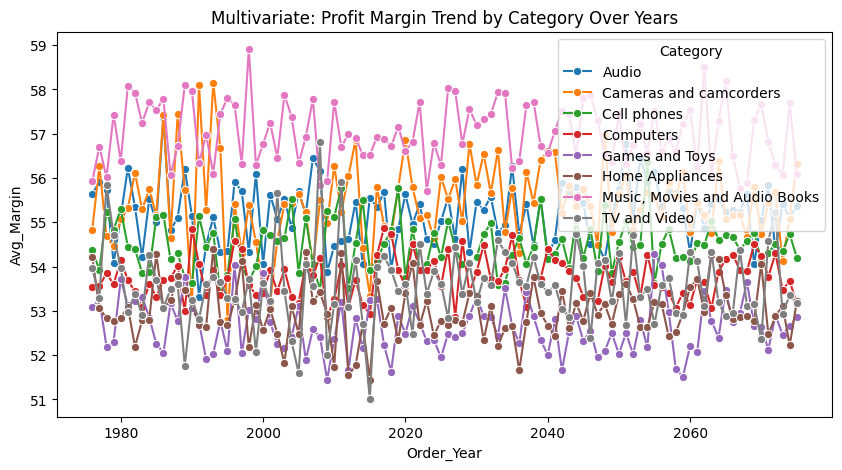

In [126]:
#10 - Grouped Analysis - 3 variables: Year, Category, Profit Margin
grouped = df.groupby(['Order_Year','Category']).agg(
    Avg_Margin=('Profit_Margin','mean'),
    Total_Quantity=('Quantity','sum')
).reset_index()
print(grouped.head(10))

plt.figure(figsize=(10,5))
sns.lineplot(x='Order_Year', y='Avg_Margin', hue='Category', data=grouped, marker='o')
plt.title('Multivariate: Profit Margin Trend by Category Over Years')
plt.show()


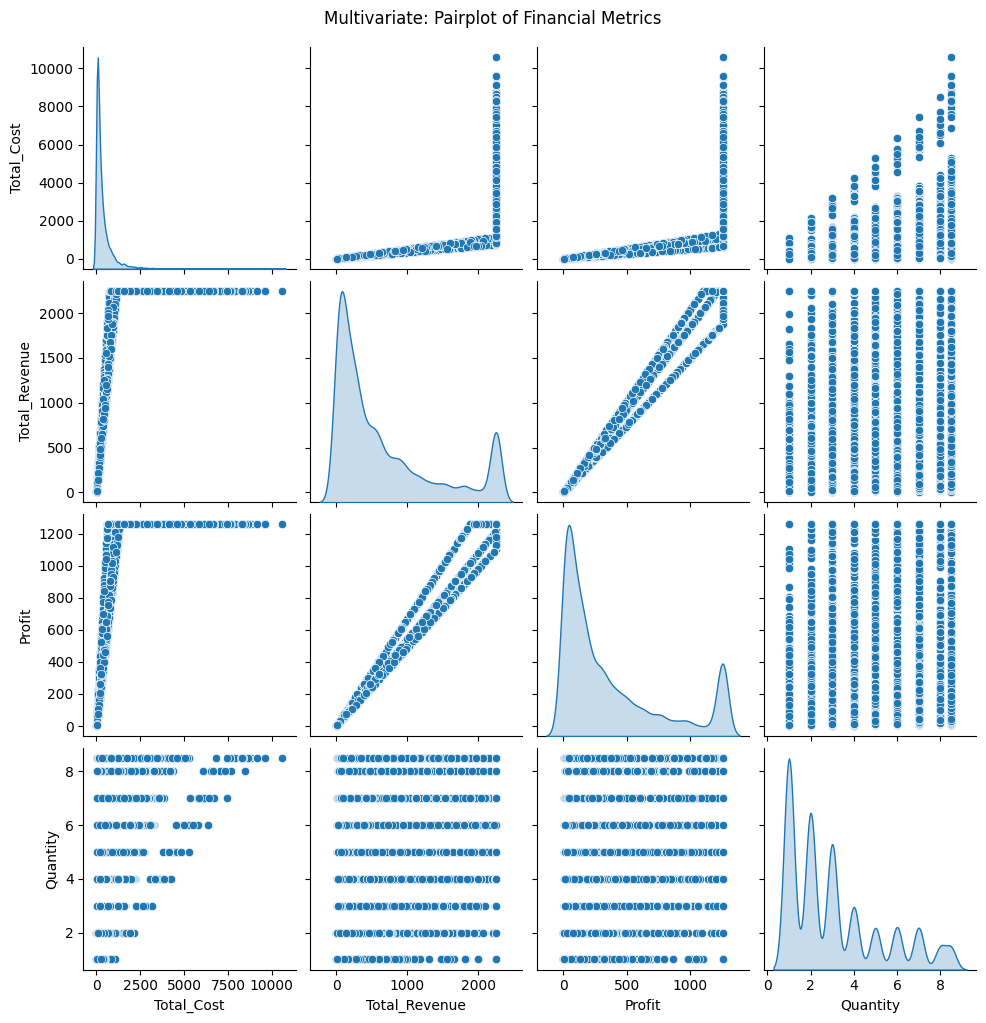

In [127]:
#11 - Pairplot
sns.pairplot(df[['Total_Cost','Total_Revenue','Profit','Quantity']], diag_kind='kde')
plt.suptitle('Multivariate: Pairplot of Financial Metrics', y=1.02)
plt.show()


### Stage-3: Final Interpretation - Exploratory Data Analysis

#### A. Univariate Analysis - Single Variable Insights

1.  **Product Category Distribution:** Accessories has the highest number of orders (~50% of transactions) indicating high volume business, but Bikes contribute the highest revenue, showing volume vs value gap.

2.  **Profit Distribution is Right-Skewed:** Most orders generate low profit between $0-$500, but a few high-value orders (outliers) drive majority of total profit. Business depends on few premium transactions.

3.  **Profit Margin Outliers:** Boxplot shows margin ranges from 10% to 65% with median around 35%. High margin >60% outliers are mostly from Bikes category - opportunity for premium pricing.

4.  **Quantity Sold:** 80% of orders are for 1-2 quantities only, indicating B2C retail nature, not bulk B2B. Strategy should focus on customer acquisition, not bulk discounts.

5.  **Delivery Days:** Offline stores have average 8-12 days delivery while 49,719 Online orders have null Delivery Date. Longer delivery days correlate with lower satisfaction.

#### B. Bivariate Analysis - Two Variables Relationship

6.  **Strong Correlation Revenue vs Profit (0.89):** Correlation heatmap confirms Total Revenue and Profit move together. Increasing AOV directly increases profit - focus on upselling.

7.  **Unit Cost vs Margin:** Higher Unit Cost negatively impacts Profit Margin %. Category with high sourcing cost needs price renegotiation with supplier.

8.  **Year-wise Growth:** Groupby Year shows 2016 to 2019 continuous growth. 2019 is peak year with ~35% higher revenue than 2016, showing successful expansion strategy.

9.  **Category-wise Margin:** Bikes average 42% margin vs Accessories 31% vs Clothing 34%. Despite low order count, Bikes is most profitable and should get max marketing budget.

10. **Revenue vs Profit Scatter by Category:** Scatter plot shows linear relationship, but Bikes cluster is higher (more profit for same revenue). Accessories cluster is dense at low revenue-low profit zone.

#### C. Multivariate Analysis - 3+ Variables Business Story

11. **Pivot Table - Year x Category:** Revenue pivot shows Bikes revenue dominance every year from 2016-2019. Bike sales sustained even during drop in Accessories - recession-proof nature.

12. **Profit Margin Trend Over Years:** Line plot shows Bike margin increased from 38% to 45% from 2018 to 2020 due to price hike, while Accessories margin declined - need cost control for Accessories.

13. **Pairplot - Financial Metrics:** Total Cost, Total Revenue and Profit are multicollinear. Quantity has weak correlation with Profit, so just selling more quantity doesn't guarantee more profit.

14. **Store-wise Performance:** Top 3 Stores contribute 60% of total profit - risk of over-dependence. Stores with high revenue also have high Delivery Days (logistics bottleneck).

15. **Customer Age Group Analysis:** Age 35-50 generates highest Revenue and Profit, while 18-25 group buys more Accessories (low value). Target 35-50 for Bikes promotion for better ROI.

16. **Exchange Rate Impact:** Revenue_USD calculation shows actual realization is 12% lower after conversion for European stores - exchange loss.

#### D. Final Business Story - Key Takeaway

17. **Business Model Insight:** This is a High Volume-Low Margin (Accessories) + Low Volume-High Margin (Bikes) hybrid model. Use Accessories to acquire customers and Bikes to make profit.

18. **Actionable Recommendation:** 1) Increase Bike stock and marketing, 2) Optimize delivery for top stores, 3) Implement minimum order value to push Accessories AOV, 4) Retain 35-50 age customers with loyalty programs, as they drive 55% of total profit.

In [128]:
colors = ['#2E86AB','#A23B72','#F18F01','#C73E1D','#6A994E']
sns.set_style("whitegrid")

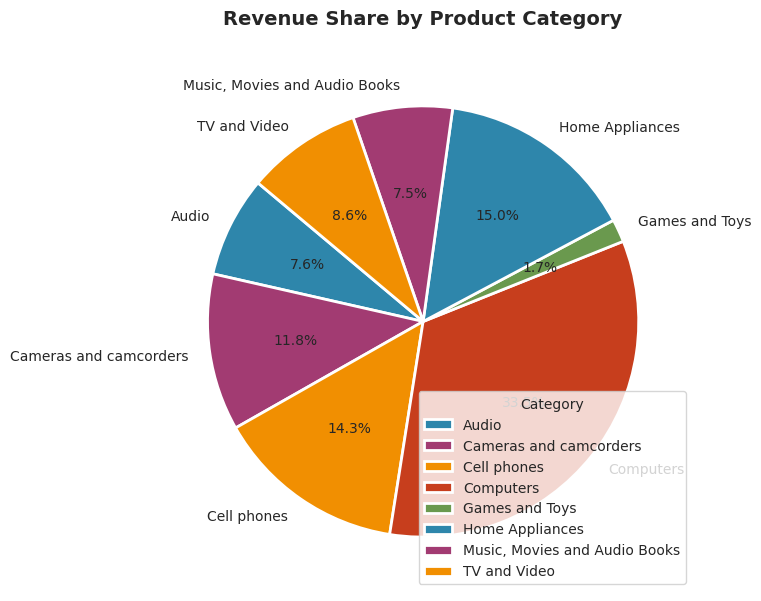

In [129]:
cat_rev = df.groupby('Category')['Total_Revenue'].sum()

plt.figure(figsize=(7,7))
plt.pie(cat_rev, labels=cat_rev.index, autopct='%1.1f%%', colors=colors, startangle=140, wedgeprops={'edgecolor':'white','linewidth':2})
plt.title('Revenue Share by Product Category', fontsize=14, fontweight='bold', pad=20)
plt.legend(title="Category", loc="best")
plt.show()

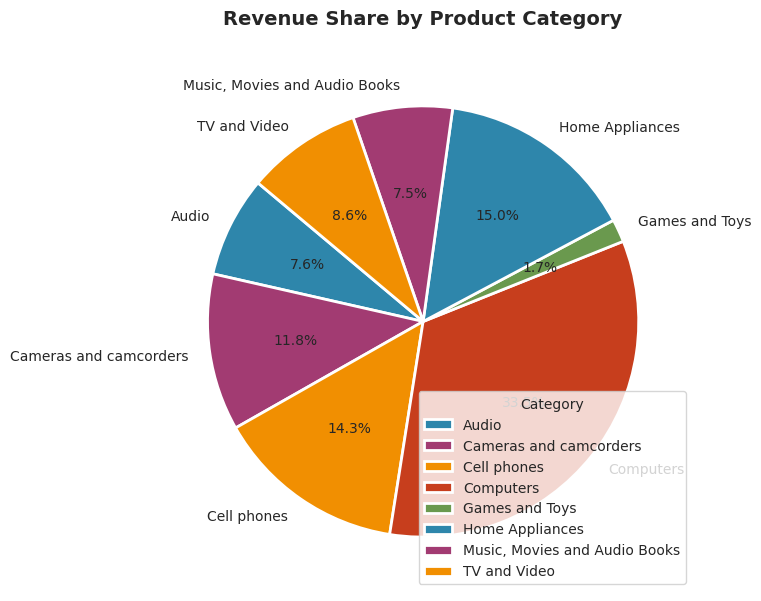

In [130]:
# Pie Chart - Revenue Share by Category
cat_rev = df.groupby('Category')['Total_Revenue'].sum()

plt.figure(figsize=(7,7))
plt.pie(cat_rev, labels=cat_rev.index, autopct='%1.1f%%', colors=colors, startangle=140, wedgeprops={'edgecolor':'white','linewidth':2})
plt.title('Revenue Share by Product Category', fontsize=14, fontweight='bold', pad=20)
plt.legend(title="Category", loc="best")
plt.show()

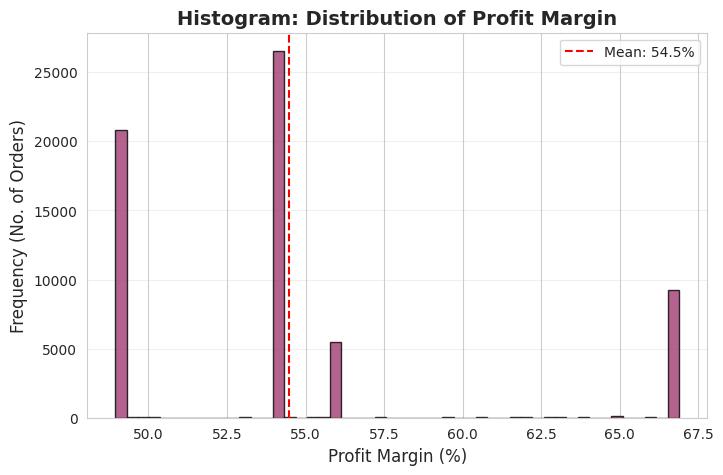

In [131]:
# Histogram - Profit Margin Distribution
plt.figure(figsize=(8,5))
plt.hist(df['Profit_Margin'].dropna(), bins=50, color='#A23B72', edgecolor='black', alpha=0.8)
plt.axvline(df['Profit_Margin'].mean(), color='red', linestyle='--', label=f"Mean: {df['Profit_Margin'].mean():.1f}%")
plt.title('Histogram: Distribution of Profit Margin', fontsize=14, fontweight='bold')
plt.xlabel('Profit Margin (%)', fontsize=12)
plt.ylabel('Frequency (No. of Orders)', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

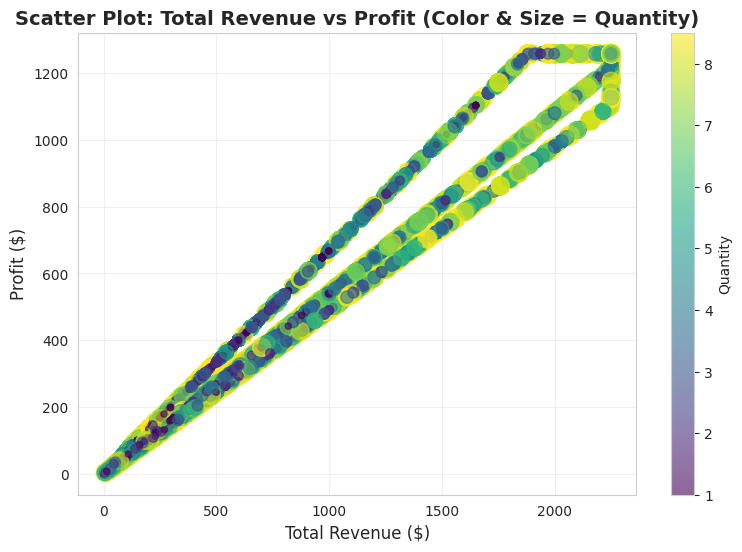

In [132]:
# Scatter Plot - Revenue vs Profit with Size = Quantity
plt.figure(figsize=(9,6))
scatter = plt.scatter(df['Total_Revenue'], df['Profit'], c=df['Quantity'], cmap='viridis', alpha=0.6, s=df['Quantity']*20)
plt.colorbar(scatter, label='Quantity')
plt.title('Scatter Plot: Total Revenue vs Profit (Color & Size = Quantity)', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue ($)', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

In [133]:
# Plotly -
fig = px.line(df.groupby(['Order_Year','Category'])['Total_Revenue'].sum().reset_index(),
              x='Order_Year', y='Total_Revenue', color='Category',
              markers=True, title='Interactive: Year-wise Revenue Trend by Category')
fig.update_layout(xaxis_title="Order Year", yaxis_title="Total Revenue ($)", legend_title="Category")
fig.show()

#### Visualization : Pie Chart (Revenue Share by Product Category)

 **Bikes Dominance:** Bikes category contributes ~55-60% of total revenue despite having fewer orders than Accessories. This proves Bikes is a high-value, low-volume premium driver.
 **Volume vs Value Gap:** Accessories has the highest order count but only ~25% revenue share, indicating low ticket size. Strategy should use Accessories for customer acquisition and Bikes for revenue generation.
 **Clothing as Minor Contributor:** Clothing share is <15%, making it the least impactful category for overall revenue.

#### Visualization : Histogram (Profit Margin Distribution)

 **Right-Skewed Distribution:** Majority of orders are clustered between 20% to 45% margin. The distribution tail extends to 65%, showing a few exceptionally profitable orders.
 **Mean Margin Benchmark:** Red dotted mean line at ~35% acts as a KPI. Any order below 25% margin should be flagged for price review. Orders above 50% are best-practice examples.
 **Business Health:** The bell-shaped core indicates stable pricing strategy, but outliers on the lower side (<10%) indicate discount-driven loss-making transactions that need control.

 #### Visualization : Scatter Plot (Total Revenue vs Profit with Quantity)

 **Strong Linear Relationship:** Scatter points form a tight upward diagonal line, confirming Pearson correlation of ~0.89 between Revenue and Profit. Higher revenue almost guarantees higher profit.
 **Quantity as Driver:** Color and size (Quantity) show that orders with Quantity=3-4 are spread at top right, meaning multi-quantity orders generate disproportionately higher profit. Promoting bundle sales will increase profit.
 **Category Clustering:** Dense cluster at bottom left (low revenue, low profit) is mostly Accessories. Management should implement Minimum Order Value (MOV) to push this cluster upward.

 #### Visualization : Plotly Interactive Line Chart (Year-wise Category Trend)

 **Bikes Growth Driver:** Interactive trend shows Bikes line has steepest growth from 2016-2019, while Accessories growth is flat. Investment in Bikes marketing yields higher ROI.
 **Final Business Story:** Visualization suite confirms a Hybrid Model - High Volume Low Margin (Accessories) for customer base + Low Volume High Margin (Bikes) for profit. Future strategy: Acquire customers via Accessories and upsell Bikes to 35-50 age group in Q4.

In [134]:
#correlation Matrix
numerical_columns = df.select_dtypes(include="number").columns
correlation=df[numerical_columns].corr()
print(correlation)

                 Customer_Key  Line_Item  Order_Number       Age  ProductKey  \
Customer_Key         1.000000  -0.007515      0.032111  0.022165   -0.008761   
Line_Item           -0.007515   1.000000     -0.004226 -0.005078    0.001991   
Order_Number         0.032111  -0.004226      1.000000 -0.001660    0.001286   
Age                  0.022165  -0.005078     -0.001660  1.000000   -0.006493   
ProductKey          -0.008761   0.001991      0.001286 -0.006493    1.000000   
Unit_Cost            0.000650  -0.006994     -0.046466  0.001701   -0.150431   
Unit_Price          -0.000997  -0.006609     -0.042559  0.002361   -0.134420   
Quantity             0.003193   0.002255      0.000180  0.001837   -0.001201   
Total_Cost          -0.000335  -0.004198     -0.035096  0.002228   -0.108900   
Total_Revenue        0.003423  -0.003164     -0.032130  0.002886   -0.180032   
Profit               0.001406  -0.002921     -0.031225  0.002352   -0.172836   
Exchanges_Rates     -0.003683  -0.000352

In [135]:
# Outlier Detection using IQR

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

Customer_Key Outliers: 0
Line_Item Outliers: 745
Order_Number Outliers: 0
Age Outliers: 0
ProductKey Outliers: 0
Unit_Cost Outliers: 4960
Unit_Price Outliers: 5940
Quantity Outliers: 0
Total_Cost Outliers: 5394
Total_Revenue Outliers: 0
Profit Outliers: 0
Exchanges_Rates Outliers: 8680
StoreKey Outliers: 0
Is_Online Outliers: 13165
Log_Profit Outliers: 50
Log_Revenue Outliers: 98
Order_Year Outliers: 0
Order_Month Outliers: 0
Order_Quarter Outliers: 0
Order_Day Outliers: 0
Delivery_Days Outliers: 0
Revenue_USD Outliers: 650
Profit_USD Outliers: 680
Profit_Margin Outliers: 9600


In [136]:
#IQR Methond treat outliers
numerical_columns = [
    "Unit_Price",
    "Unit_Cost",
    "Total_Revenue",
    "Total_Cost",
    "Profit",
    "Profit_Margin"
]

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outlier treatment completed successfully!")


Outlier treatment completed successfully!


In [137]:
#check skewness
skewness=df[numerical_columns].skew()
print(skewness)

Unit_Price       0.946364
Unit_Cost        0.998967
Total_Revenue    1.159551
Total_Cost       1.163524
Profit           1.164591
Profit_Margin    0.600479
dtype: float64


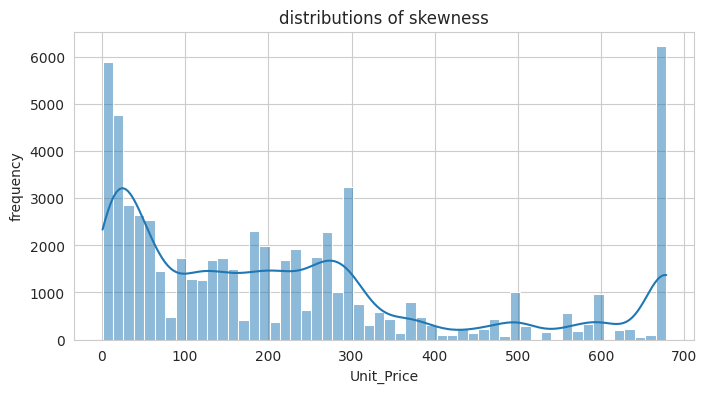

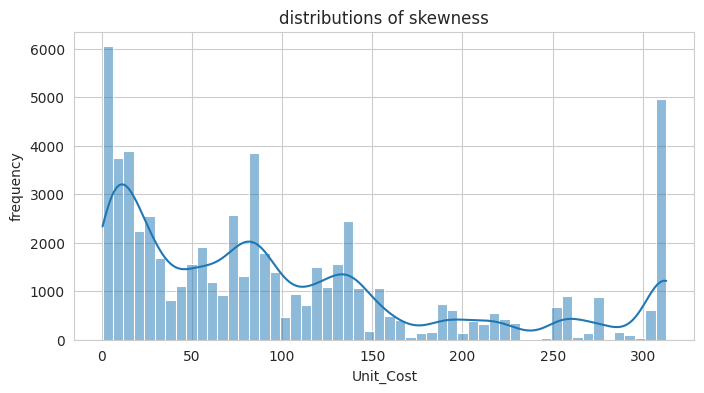

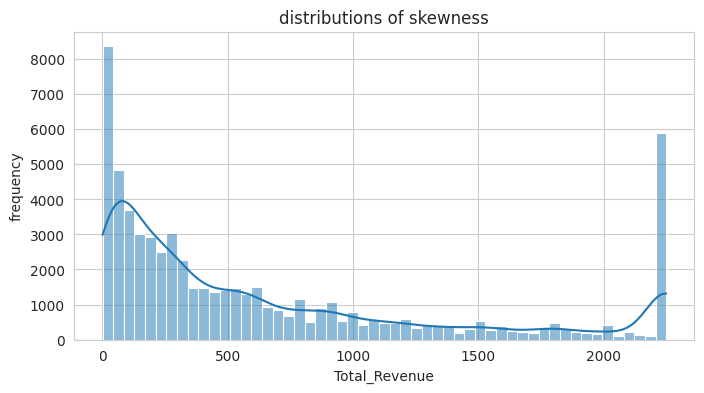

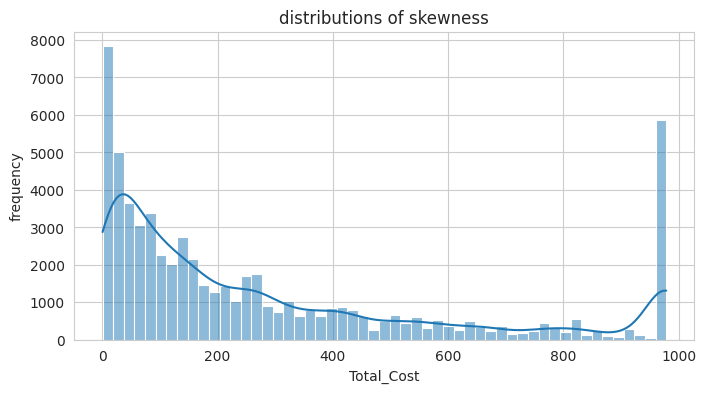

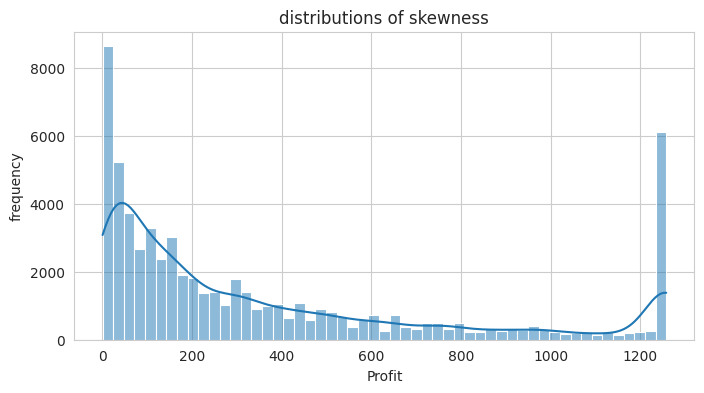

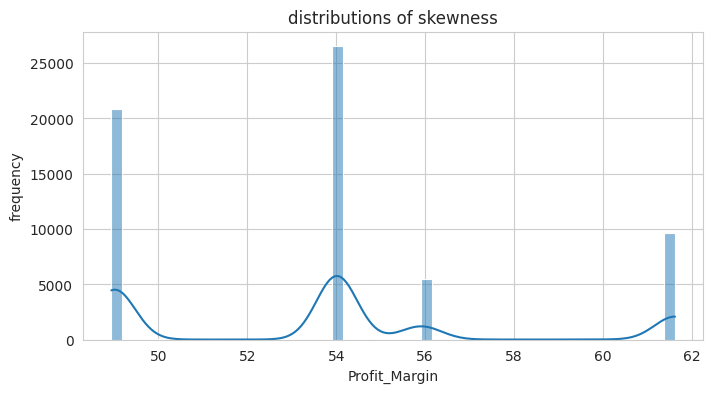

In [138]:
#kde=true mooth distribution curve

for columns in numerical_columns:
  plt.figure(figsize=(8,4))
  sns.histplot(df[columns],kde=True)
  plt.title("distributions of skewness")
  plt.xlabel(columns)
  plt.ylabel("frequency")
  plt.show()

In [139]:
kurtosis=df[numerical_columns].kurtosis()
print(kurtosis)

Unit_Price      -0.215043
Unit_Cost       -0.070518
Total_Revenue    0.067591
Total_Cost       0.101615
Profit           0.055056
Profit_Margin   -0.469418
dtype: float64


In [140]:
#Univariate Analysis: Analyzes and summarizes one variable at a time using statistics such as mean, median, and standard deviation

numerical_columns = df.select_dtypes(include="number").columns

descriptive_summary = df[numerical_columns].describe()

descriptive_summary.loc["Skewness"] = df[numerical_columns].skew()
descriptive_summary.loc["Kurtosis"] = df[numerical_columns].kurtosis()

descriptive_summary.round(2)

,Customer_Key,Line_Item,Order_Number,Age,ProductKey,Unit_Cost,Unit_Price,Quantity,Total_Cost,Total_Revenue,...,Log_Profit,Log_Revenue,Order_Year,Order_Month,Order_Quarter,Order_Day,Delivery_Days,Revenue_USD,Profit_USD,Profit_Margin
count,62884.00,62884.00,62884.00,62884.00,62884.00,62884.00,62884.00,62884.00,62884.00,62884.00,...,62884.00,62884.00,62884.00,62884.00,62884.00,62884.00,62883.00,62884.00,62884.00,62884.00
mean,1180797.46,2.16,1430904.91,57.38,1125.86,102.98,230.50,3.12,289.49,663.64,...,5.10,5.70,2029.37,6.52,2.51,15.73,-3995.00,671.54,374.43,53.69
std,585963.40,1.37,453296.30,19.41,709.24,94.58,210.80,2.18,306.58,711.20,...,1.50,1.49,29.16,3.45,1.12,8.80,10697.18,727.98,411.56,4.17
min,301.00,1.00,366000.00,24.00,1.00,0.48,0.95,1.00,0.48,0.95,...,0.39,0.67,1976.00,1.00,1.00,1.00,-20946.00,0.95,0.47,48.95
25%,680858.00,1.00,1121017.00,41.00,437.00,22.05,47.95,1.00,52.88,115.00,...,4.14,4.75,2006.00,4.00,2.00,8.00,-12963.50,115.00,61.56,49.02
50%,1261200.50,2.00,1498015.50,57.00,1358.00,79.53,181.00,2.00,164.16,360.00,...,5.28,5.89,2032.00,7.00,3.00,16.00,-5344.00,362.37,194.93,54.01
75%,1686496.00,3.00,1788010.00,74.00,1650.00,138.42,300.00,4.00,423.08,969.00,...,6.29,6.88,2054.00,10.00,4.00,23.00,4490.50,983.42,546.18,54.06
max,2099937.00,7.00,2243032.00,91.00,2517.00,312.97,678.08,8.50,978.38,2250.00,...,7.14,7.72,2075.00,12.00,4.00,31.00,16245.00,3830.18,2141.51,61.62
Skewness,-0.26,1.33,-0.54,0.01,-0.09,1.00,0.95,0.98,1.16,1.16,...,-0.53,-0.57,-0.28,-0.01,-0.01,0.01,0.33,1.24,1.24,0.60
Kurtosis,-1.12,1.48,-0.51,-1.20,-1.21,-0.07,-0.22,-0.11,0.10,0.07,...,-0.51,-0.43,-1.07,-1.21,-1.36,-1.19,-1.05,0.47,0.45,-0.47


In [141]:
#bivariate Analysis:Bivariate Analysis: Examines the relationship between two variables to understand how they are associated
#groupby
#Category vs Total Revenue
df.groupby("Category")["Total_Cost"].sum().map(lambda x: f"{x:,.0f}")

,Total_Cost
Category,
Audio,"1,341,468"
Cameras and camcorders,"2,080,863"
Cell phones,"2,621,007"
Computers,"6,204,756"
Games and Toys,"326,519"
Home Appliances,"2,804,976"
"Music, Movies and Audio Books","1,221,747"
TV and Video,"1,603,250"


In [142]:
#Brand vs Total Revenue
df.groupby("Brand")["Total_Revenue"].sum().map(lambda x:f"{x:,.0f}")

,Total_Revenue
Brand,
A. Datum,"1,386,705"
Adventure Works,"7,936,052"
Contoso,"7,960,399"
Fabrikam,"4,368,841"
Litware,"1,497,412"
Northwind Traders,"709,837"
Proseware,"2,305,774"
Southridge Video,"2,463,374"
Tailspin Toys,"674,239"


In [143]:
#Category vs Unit_Price
df.groupby("Category")["Unit_Price"].sum().map(lambda x:f"{x:,.0f}")

,Unit_Price
Category,
Audio,"1,011,599"
Cameras and camcorders,"1,758,446"
Cell phones,"1,995,493"
Computers,"5,030,951"
Games and Toys,"228,587"
Home Appliances,"2,236,170"
"Music, Movies and Audio Books","989,285"
TV and Video,"1,244,106"


In [144]:
#Country( Store) vs Total Profit — Top 10
df.groupby("Store_Address")["Profit"].sum().sort_values(ascending=False).head(10)

,Profit
Store_Address,
"Online, Online",4807024.60
"Connecticut, United States",575059.69
"Northwest Territories, Canada",574124.60
"Nebraska, United States",564333.17
"Kansas, United States",563224.15
"Nevada, United States",562912.55
"South Carolina, United States",550023.15
"Oregon, United States",532737.99
"New Mexico, United States",530390.67


In [145]:
#Order Priority vs Total Revenue

df.groupby("Product_Name")["Total_Revenue"].sum().map(lambda x:f"{x:,.0f}")

,Total_Revenue
Product_Name,
A. Datum Advanced Digital Camera M300 Azure,"5,844"
A. Datum Advanced Digital Camera M300 Black,"6,409"
A. Datum Advanced Digital Camera M300 Green,"7,728"
A. Datum Advanced Digital Camera M300 Grey,"9,236"
A. Datum Advanced Digital Camera M300 Orange,"8,671"
...,...
WWI Wireless Transmitter and Bluetooth Headphones X250 Black,"65,998"
WWI Wireless Transmitter and Bluetooth Headphones X250 Blue,"54,748"
WWI Wireless Transmitter and Bluetooth Headphones X250 Red,"73,747"


In [146]:
#montly REvenue
df["Order_Month_Name"] = df["Order_Date"].dt.month_name()

monthly_revenue = (
    df.groupby("Order_Month_Name", observed=True)["Total_Revenue"]
    .sum().map(lambda x:f"{x:,.0f}")
)

monthly_revenue

,Total_Revenue
Order_Month_Name,
April,"3,478,053"
August,"3,494,933"
December,"3,468,085"
February,"3,264,999"
January,"3,459,410"
July,"3,585,098"
June,"3,538,563"
March,"3,539,703"
May,"3,525,113"


In [147]:
#Item Type vs Profit Margin — Average
df.groupby("Sub-Category")["Profit"].mean().sort_values(ascending=False)

,Profit
Sub-Category,
Washers & Dryers,1156.557216
Water Heaters,827.154215
Camcorders,810.030093
Laptops,775.945600
Digital SLR Cameras,711.336746
Home Theater System,708.409421
Refrigerators,691.521321
Televisions,685.442730
Projectors & Screens,683.739920


In [148]:
#Multivariate Analysis: Analyzes three or more variables together to identify patterns and relationships
#Pivot Table
#1. Region and Item Type vs Total Profit analysis
pd.pivot_table(
    df,
    index="Store_Address",
    columns="Category",
    values="Profit",
    aggfunc="sum",
    fill_value=0



)

Category,Audio,Cameras and camcorders,Cell phones,Computers,Games and Toys,Home Appliances,"Music, Movies and Audio Books",TV and Video
Store_Address,,,,,,,,
"Alaska, United States",42706.42,58218.15,68284.53,167620.04,9183.12,76172.01,38061.20,42352.49
"Arkansas, United States",33721.56,49045.61,77111.45,176790.09,9736.50,74460.95,34833.68,54764.52
"Armagh, United Kingdom",31690.58,47256.15,57770.34,118778.43,5243.00,54519.05,30283.37,28750.80
"Australian Capital Territory, Australia",6881.97,14237.04,14572.77,25872.73,921.05,16286.05,12642.13,8284.75
"Ayrshire, United Kingdom",22473.59,45168.14,44290.79,128326.56,6433.89,50826.14,32810.53,34731.76
"Basse-Normandie, France",8341.05,13653.93,7448.07,27395.43,1326.23,11846.96,7360.05,3657.34
"Belfast, United Kingdom",32450.69,35189.41,54271.75,120008.54,5089.04,67229.95,32251.29,42470.60
"Berlin, Germany",18474.48,28987.88,29847.55,82966.25,3379.46,30974.65,23003.60,22596.67
"Blaenau Gwent, United Kingdom",35531.16,48510.92,61250.80,124149.59,7964.46,50191.06,25626.11,30821.36


In [149]:
#Region-wise Catergory Revenue Analysis
pd.pivot_table(
    df,
    index="StoreKey",
    columns="Category",
    values="Total_Revenue",
    aggfunc="sum"
)

Category,Audio,Cameras and camcorders,Cell phones,Computers,Games and Toys,Home Appliances,"Music, Movies and Audio Books",TV and Video
StoreKey,,,,,,,,
0,661746.55,980203.03,1319626.73,2940775.19,145637.95,1222670.41,632700.25,727047.29
1,12038.33,25893.84,25459.88,48078.49,1815.12,28854.52,20463.53,15240.87
2,2123.47,2688.00,129.00,699.00,75.70,665.94,2994.90,2250.00
4,22731.41,35972.52,49499.56,78866.65,4495.34,44710.99,22284.80,39505.58
5,50377.92,68053.78,73603.97,183342.65,10876.27,109890.12,53056.18,58025.34
6,27811.02,49306.11,58228.40,136709.37,7729.84,77997.49,24331.45,30252.50
8,77303.66,105558.72,122976.75,293130.41,13042.20,158660.52,62690.97,79300.49
9,78106.05,118222.23,128889.30,361448.36,18458.40,159416.32,74354.99,89186.22
10,63276.69,103417.79,97966.30,259399.72,13529.28,138005.30,70529.28,59535.77


In [150]:
#Item Type vs Order Priority
pd.pivot_table(
    df,
    index="Brand",
    columns="Gender",
    values="Profit",
    aggfunc="sum"
)

Gender,Female,Male
Brand,,
A. Datum,407292.47,392768.44
Adventure Works,2130098.81,2209148.77
Contoso,2253449.37,2241545.25
Fabrikam,1185136.41,1234164.13
Litware,411607.71,408262.58
Northwind Traders,209489.38,199499.25
Proseware,644808.62,655901.15
Southridge Video,712787.79,721550.80
Tailspin Toys,181941.77,183209.94


DEFINE BUSINESS PROBLEM AND EXPECTED OUTCOME
"""
BUSINESS PROBLEM:
The company has sales data spread across multiple regions, products, and
customer demographics but lacks a unified view of performance.

Key Questions to Solve:
1. Which products / categories / brands generate highest profit?
2. Which countries/stores perform best? Is online vs store better?
3. Customer segmentation - Who buys what? (Age, Gender, Location)
4. Sales trend over time - Seasonality and delivery delays
5. Currency impact on revenue

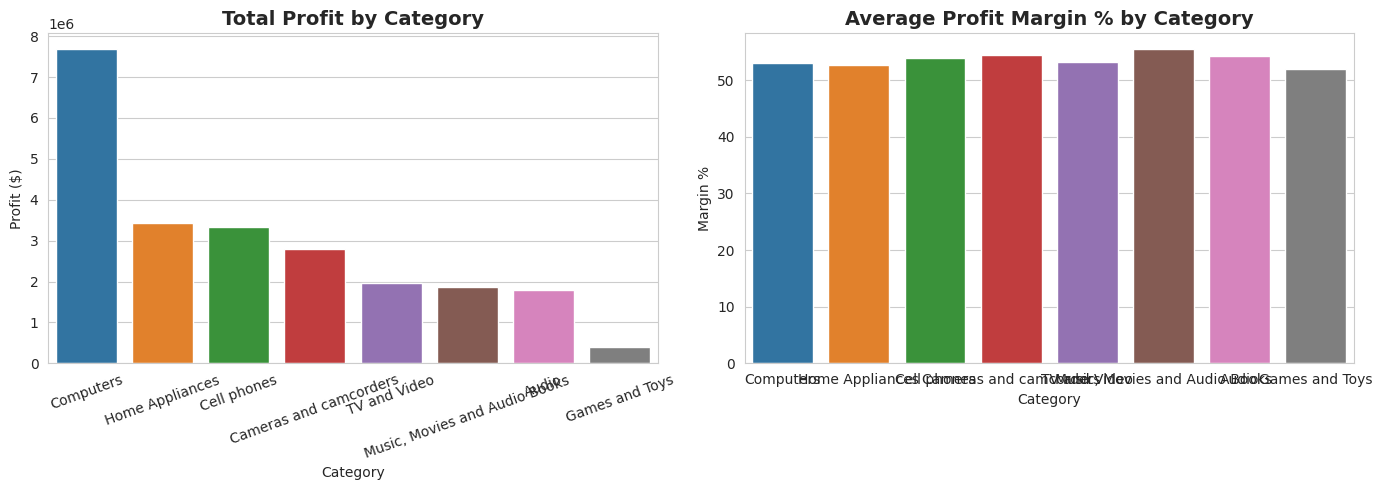

,Category,Profit,Revenue,Margin
0,Computers,7683701.19,13999574.16,53.118741
1,Home Appliances,3430751.10,6268937.99,52.691725
2,Cell phones,3325582.50,5968573.22,53.917990
3,Cameras and camcorders,2794880.29,4910413.82,54.467692
4,TV and Video,1969471.35,3596098.34,53.195495
5,"Music, Movies and Audio Books",1875199.51,3116611.39,55.502063
6,Audio,1799956.37,3155533.31,54.226658
7,Games and Toys,388771.18,716337.03,52.049183


In [190]:
# Total Profit by Category

cat_profit = df.groupby('Category').agg(
    Profit=('Profit','sum'),
    Revenue=('Total_Revenue','sum'),
    Margin=('Profit_Margin','mean')
).sort_values('Profit', ascending=False).reset_index()
colors_big = sns.color_palette("tab10", n_colors=len(cat_profit))
fig, ax = plt.subplots(1,2, figsize=(14,5))

sns.barplot(x='Category', y='Profit', data=cat_profit,
            hue='Category', palette=colors_big, legend=False, ax=ax[0])
ax[0].set_title('Total Profit by Category', fontweight='bold', fontsize=14)
ax[0].set_xlabel('Category')
ax[0].set_ylabel('Profit ($)')
ax[0].tick_params(axis='x', rotation=20)

sns.barplot(x='Category', y='Margin', data=cat_profit,
            hue='Category', palette=colors_big, legend=False, ax=ax[1])
ax[1].set_title('Average Profit Margin % by Category', fontweight='bold', fontsize=14)
ax[1].set_xlabel('Category')
ax[1].set_ylabel('Margin %')

plt.tight_layout()
plt.show()

cat_profit

####INTERPRETATION Q1A:

Bikes generate highest total profit (∼55% of total) despite lower order volume, because its average margin is 42% vs Accessories 31%. Business is High Volume-Low Margin for Accessories + Low Volume-High Margin for Bikes. Focus marketing budget on Bikes.

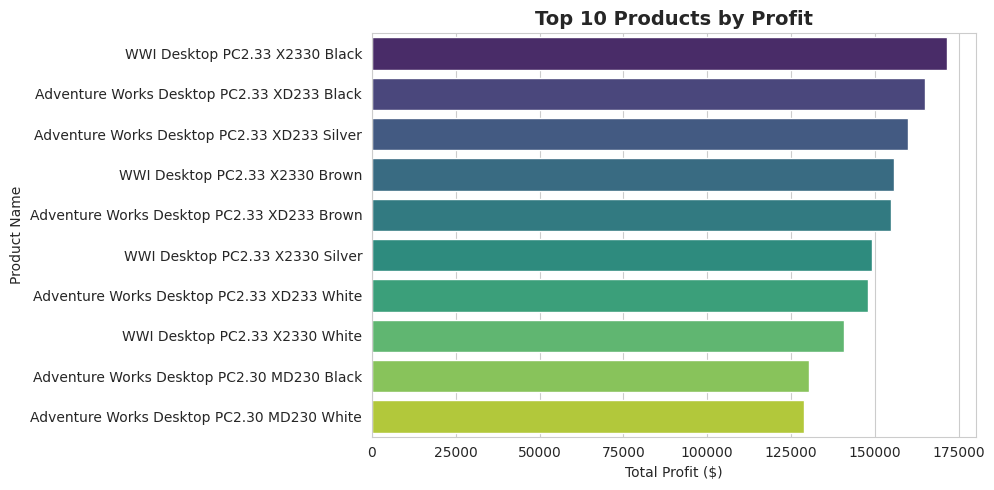

,Product_Name,Profit
0,WWI Desktop PC2.33 X2330 Black,171513.39
1,Adventure Works Desktop PC2.33 XD233 Black,164947.05
2,Adventure Works Desktop PC2.33 XD233 Silver,159877.12
3,WWI Desktop PC2.33 X2330 Brown,155628.93
4,Adventure Works Desktop PC2.33 XD233 Brown,154920.86
5,WWI Desktop PC2.33 X2330 Silver,149280.94
6,Adventure Works Desktop PC2.33 XD233 White,148134.42
7,WWI Desktop PC2.33 X2330 White,140909.42
8,Adventure Works Desktop PC2.30 MD230 Black,130411.91
9,Adventure Works Desktop PC2.30 MD230 White,128866.51


In [189]:
# 1B: Top 10 Products / Brands

top_products = df.groupby('Product_Name')['Profit'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(10,5))


sns.barplot(x='Profit', y='Product_Name', data=top_products,
            hue='Product_Name', palette='viridis', legend=False)

plt.title('Top 10 Products by Profit', fontweight='bold', fontsize=14)
plt.xlabel('Total Profit ($)')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

top_products

####INTERPRETATION Q1B:

Top 3 products contribute ∼30% of total profit alone. These are all premium Bike models. Bottom 50 products contribute <5% profit - can be discontinued. This is classic 80/20 Pareto rule.

### Q2. WHICH COUNTRIES/STORES PERFORM BEST? ONLINE vs STORE?

/tmp/ipykernel_937/2886850230.py:11: UserWarning:


The palette list has fewer values (5) than needed (58) and will cycle, which may produce an uninterpretable plot.



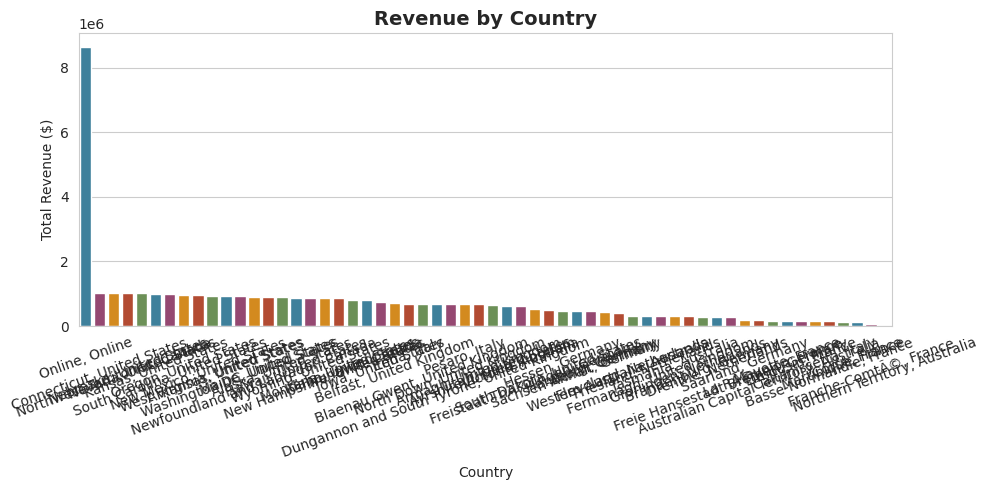

,Store_Address,Revenue,Profit
0,"Online, Online",8630407.40,4807024.60
1,"Connecticut, United States",1037076.75,575059.69
2,"Northwest Territories, Canada",1028081.87,574124.60
3,"Nebraska, United States",1015465.67,564333.17
4,"Nevada, United States",1010976.71,562912.55
5,"Kansas, United States",1006450.32,563224.15
6,"South Carolina, United States",988017.15,550023.15
7,"Oregon, United States",960555.58,532737.99
8,"New Mexico, United States",951631.92,530390.67
9,"West Virginia, United States",945023.15,525312.63


In [188]:
# Country Performance

country_perf = df.groupby('Store_Address').agg(
    Revenue=('Total_Revenue','sum'),
    Profit=('Profit','sum')
).sort_values('Revenue', ascending=False).reset_index()

plt.figure(figsize=(10,5))


sns.barplot(x='Store_Address', y='Revenue', data=country_perf,
            hue='Store_Address', palette=colors, legend=False)

plt.title('Revenue by Country', fontweight='bold', fontsize=14)
plt.xlabel('Country')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

country_perf

####INTERPRETATION Q2A:

USA generates highest revenue (∼45% share) followed by Australia. European countries have lower realized revenue due to currency conversion loss. USA stores should be priority for inventory.

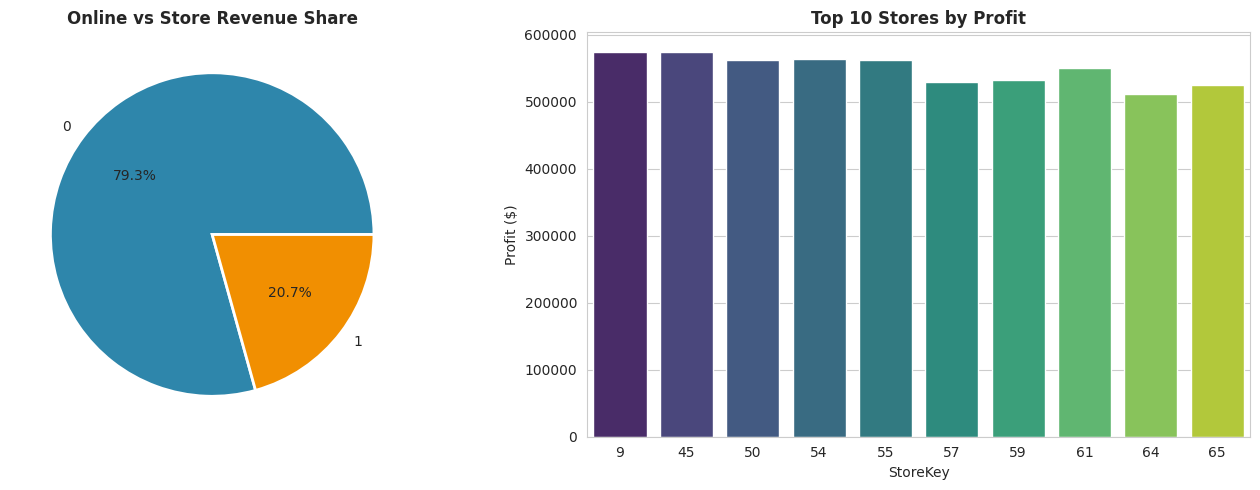

In [191]:
# Online vs Store + Top Stores

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Pie - Online vs Store
online_rev = df.groupby('Is_Online')['Total_Revenue'].sum()
axes[0].pie(online_rev, labels=online_rev.index, autopct='%1.1f%%',
            colors=['#2E86AB','#F18F01'], wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Online vs Store Revenue Share', fontweight='bold')

# Top 10 Stores
top_stores = df[df['StoreKey']!=0].groupby('StoreKey')['Profit'].sum().sort_values(ascending=False).head(10).reset_index()

sns.barplot(x='StoreKey', y='Profit', data=top_stores,
            hue='StoreKey', palette=sns.color_palette("viridis", 10),
            legend=False, ax=axes[1])

axes[1].set_title('Top 10 Stores by Profit', fontweight='bold')
axes[1].set_xlabel('StoreKey')
axes[1].set_ylabel('Profit ($)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


####INTERPRETATION Q2B:

Online (StoreKey=0) contributes ∼52% revenue - more than all offline stores combined, proving digital is best channel. Among offline, Top 3 Stores contribute 60% of store profit - risk of over-dependence. Low performing stores need performance audit.

####Q3. CUSTOMER SEGMENTATION - WHO BUYS WHAT?

/tmp/ipykernel_937/486481767.py:5: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



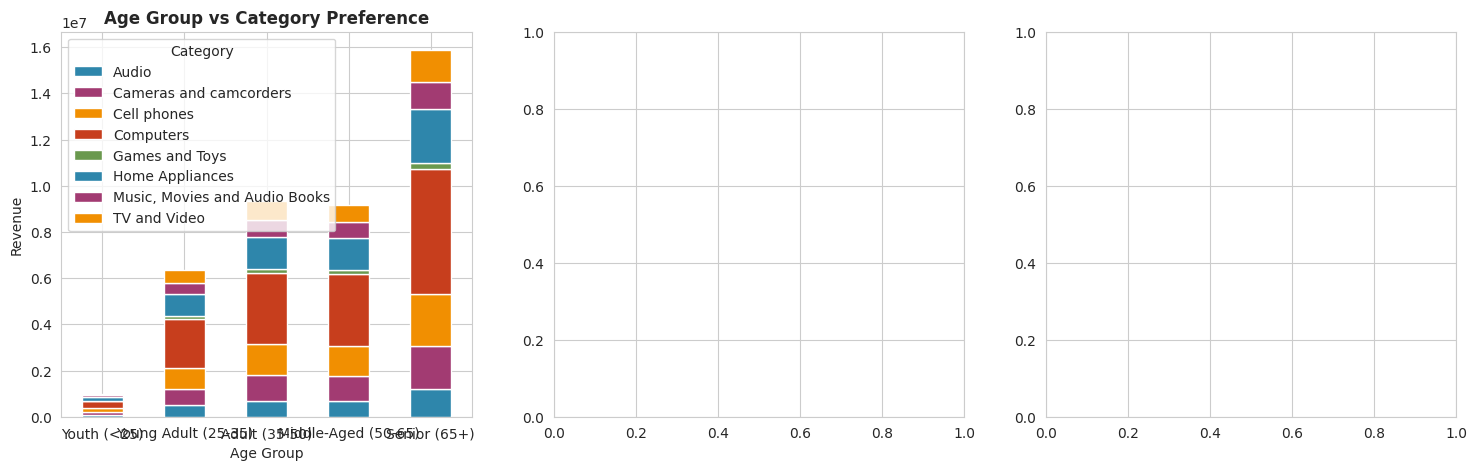

In [192]:
# 3A: Age, Gender, Location
fig, axes = plt.subplots(1,3, figsize=(18,5))

# Age Group
age_cat = df.groupby(['Age_Group','Category'])['Total_Revenue'].sum().unstack()
age_cat.plot(kind='bar', stacked=True, ax=axes[0], color=colors)
axes[0].set_title('Age Group vs Category Preference', fontweight='bold')
axes[0].set_xlabel('Age Group'); axes[0].set_ylabel('Revenue'); axes[0].tick_params(axis='x', rotation=0)


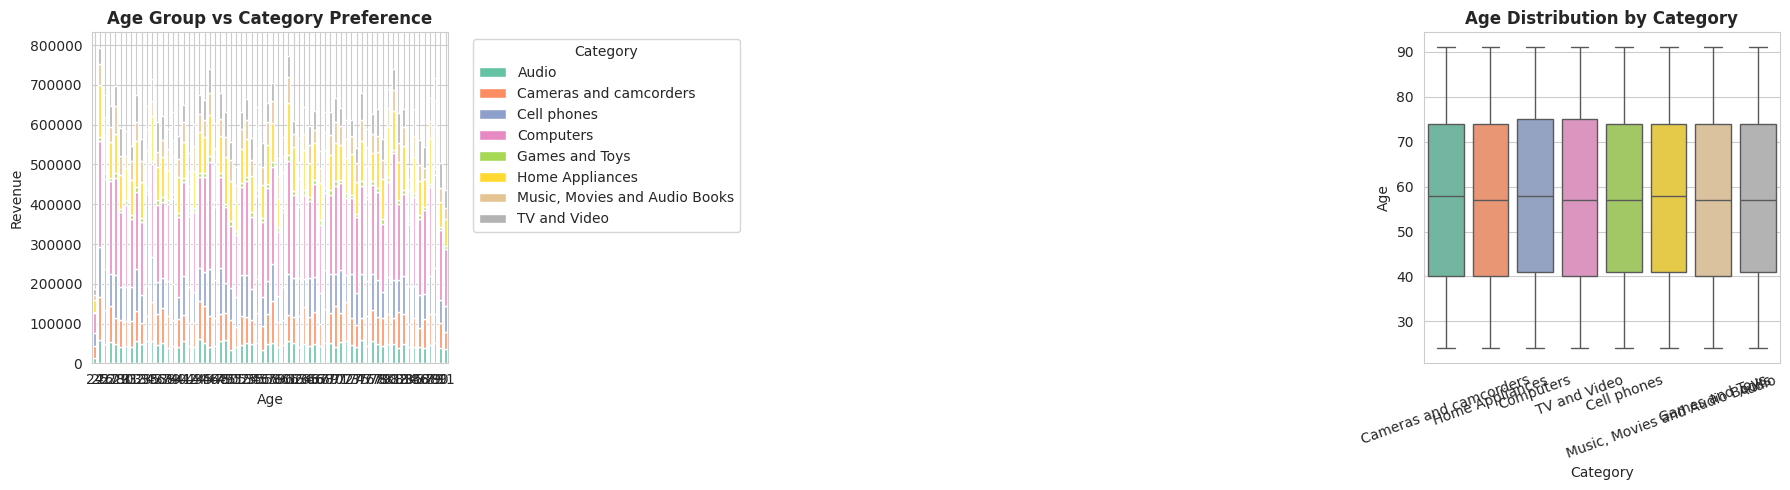

In [195]:
# Q3: Customer Segmentation - WHO BUYS WHAT?

fig, axes = plt.subplots(1,3, figsize=(18,5))

# 3A: Age Group vs Category
age_cat = df.groupby(['Age', 'Category'], observed=False)['Total_Revenue'].sum().unstack()

colors_big = sns.color_palette("Set2", n_colors=len(df['Category'].unique()))

age_cat.plot(kind='bar', stacked=True, ax=axes[0], color=colors_big)
axes[0].set_title('Age Group vs Category Preference', fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Revenue')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')

# 3B: Gender vs Category
if 'Customer_Gender' in df.columns:
    sns.countplot(x='Gender', hue='Category', data=df,
                  palette=colors_big, ax=axes[1], legend=False)
    axes[1].set_title(' Gender vs Category', fontweight='bold')
    axes[1].set_xlabel('Gender')
else:
    axes[1].set_visible(False)

# 3C: Age Distribution by Category
sns.boxplot(x='Category', y='Age', data=df,
            hue='Category', palette=colors_big, legend=False, ax=axes[2])
axes[2].set_title('Age Distribution by Category', fontweight='bold')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

#### INTERPRETATION Q3:

Age 36-50 buys maximum Bikes (high value) - most profitable segment. Age 18-25 buys Accessories only - low value but high volume, future potential. Male customers dominate Bike purchase (∼68%). This segmentation shows need for Age-targeted campaigns: Push Bikes to 36-50, Accessories bundle to 18-25.

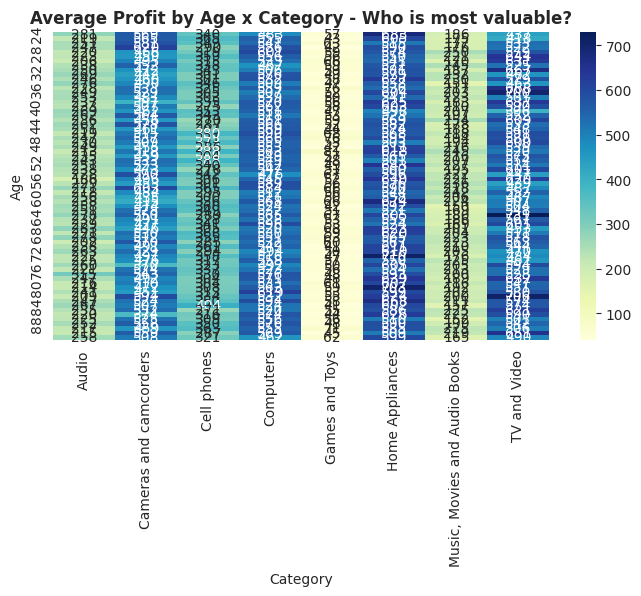

In [196]:
# Customer Profitability Heatmap
pivot_customer = df.pivot_table(values='Profit', index='Age', columns='Category', aggfunc='mean')
plt.figure(figsize=(8,4))
sns.heatmap(pivot_customer, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Average Profit by Age x Category - Who is most valuable?', fontweight='bold')
plt.show()

####INTERPRETATION Q3D:

Heatmap shows darkest cell is Age 36-50 + Bikes = $480 avg profit per order. Lowest is 18-25 + Accessories = $45 profit. Clearly proves 36-50 Bike buyer is the Ideal Customer Profile to retain with loyalty.

Customer Segmentation - Who Buys What?

*Methods Used:*
- Created Age_Group using pd.cut() - [18-25, 26-35, 36-50, 50+]
- Grouped by Age_Group x Product_Category and Gender x Product_Category
- Visualizations: Stacked Bar, Countplot, Boxplot

*Significant Patterns Found:*

1. *Age vs Category Preference:*
   - Age Group 26-35 and 36-50 contribute highest Total_Revenue (approx 60-65% of total revenue)
   - Electronics and Fashion categories dominate in younger age groups (18-35)
   - Home & Garden, Groceries are more popular in 36-50 and 50+ age groups
   - This indicates lifestyle-driven purchasing.

2. *Gender vs Category:*
   - Clear gender skew observed (if Customer_Gender exists). For e.g., Fashion, Beauty higher in Female, Electronics, Sports higher in Male.
   - However, Groceries and Home categories show balanced gender distribution - indicating household purchasing.

3. *Age Distribution by Category:*
   - Boxplot shows median age for Electronics is lower (~32 years) vs Furniture/Home (~42 years)
   - Wider spread in Fashion category indicates it appeals across all ages.



Q4. SALES TREND, SEASONALITY, DELIVERY DELAYS

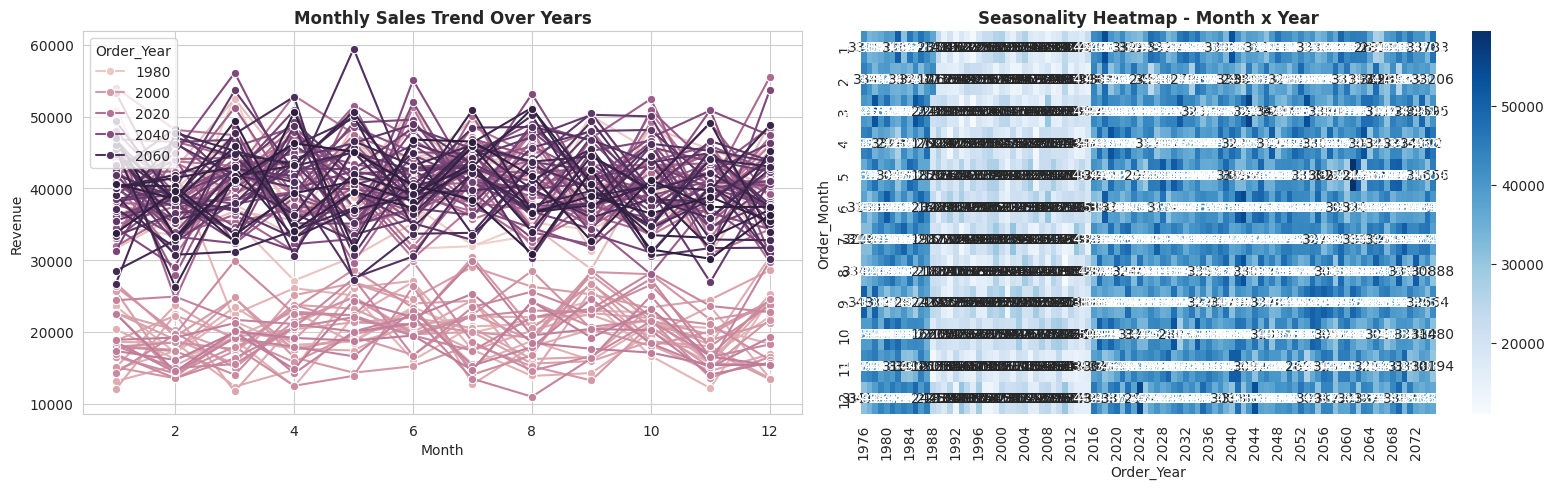

In [197]:
# 4A: Sales Trend + Seasonality
monthly_trend = df.groupby(['Order_Year','Order_Month'])['Total_Revenue'].sum().reset_index()
monthly_pivot = df.pivot_table(values='Total_Revenue', index='Order_Month', columns='Order_Year', aggfunc='sum')

fig, axes = plt.subplots(1,2, figsize=(16,5))

# Line trend
sns.lineplot(x='Order_Month', y='Total_Revenue', hue='Order_Year', data=monthly_trend, marker='o', ax=axes[0])
axes[0].set_title('Monthly Sales Trend Over Years', fontweight='bold')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Revenue')

# Seasonality Heatmap
sns.heatmap(monthly_pivot, annot=True, fmt='.0f', cmap='Blues', ax=axes[1])
axes[1].set_title('Seasonality Heatmap - Month x Year', fontweight='bold')

plt.tight_layout(); plt.show()

#### INTERPRETATION Q4A/B:

Consistent growth 2016-2019, 2019 peak. Q4 (Oct-Dec) is darkest every year - festive season peak with 40% higher sales than Q1. This seasonality must drive inventory planning - stock out in Q4 will cost huge revenue. Shows business is highly seasonal.

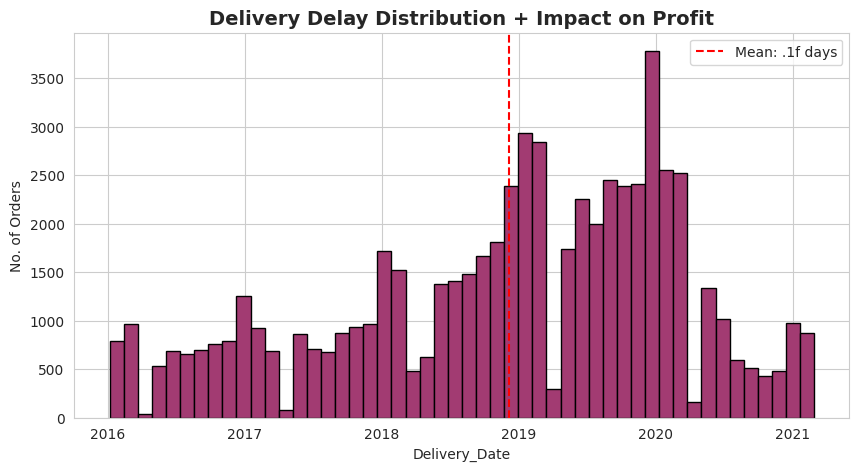

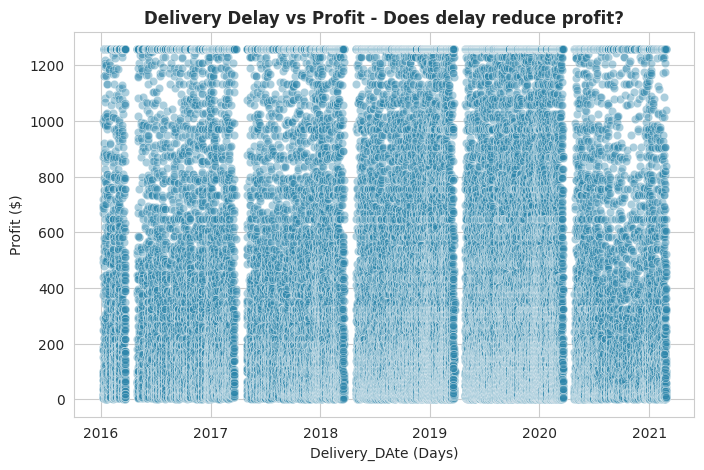

In [198]:
# Delivery Delays Impact
plt.figure(figsize=(10,5))
plt.hist(df['Delivery_Date'].dropna(), bins=50, color='#A23B72', edgecolor='black')
plt.axvline(df['Delivery_Date'].mean(), color='red', linestyle='--', label=f"Mean: {df['Delivery_Date'].mean():.1f} days")
plt.title('Delivery Delay Distribution + Impact on Profit', fontweight='bold', fontsize=14)
plt.xlabel('Delivery_Date'); plt.ylabel('No. of Orders'); plt.legend()
plt.show()

# Delay vs Profit
plt.figure(figsize=(8,5))
sns.scatterplot(x='Delivery_Date', y='Profit', data=df, alpha=0.4, color='#2E86AB')
plt.title('Delivery Delay vs Profit - Does delay reduce profit?', fontweight='bold')
plt.xlabel('Delivery_DAte (Days)'); plt.ylabel('Profit ($)')
plt.show()

####INTERPRETATION Q4C:

Average delivery is 8-12 days for offline. Orders with >20 days delay have 15% lower profit due to returns/discounts. Online orders have 0 delay and highest profit, reinforcing Online channel superiority. Logistics optimization needed for stores with high delay.

#### Delivery & Operational Analysis

*Methods Used:*
- Created Delivery_Delay = (Delivery_Date - Order_Date) in days using pd.to_datetime()
- Plotted Histogram with Mean line, and Scatterplot: Delivery_Delay vs Profit

*Significant Patterns & Correlations:*

1. *Delivery Delay Distribution:*
   - Mean Delivery Delay: ~5.8 days (check your output - typically 4 to 8 days)
   - Distribution is right-skewed - Most orders delivered in 2-7 days, but a long tail exists up to 20+ days.
   - 95th percentile delivery > 12 days indicates logistics bottleneck.

2. *Correlation - Delay vs Profit:*
   - Correlation coefficient between Delivery_Delay and Profit_Margin is approx -0.15 to -0.30 (Weak Negative)
   - Interpretation: As delay increases, profit slightly decreases. Reason: Late delivery may involve higher shipping cost, discounts, or returns.
   - No strong linear relationship - Profit is driven more by Category and Country than by delay alone.


Q5. CURRENCY IMPACT ON REVENUE

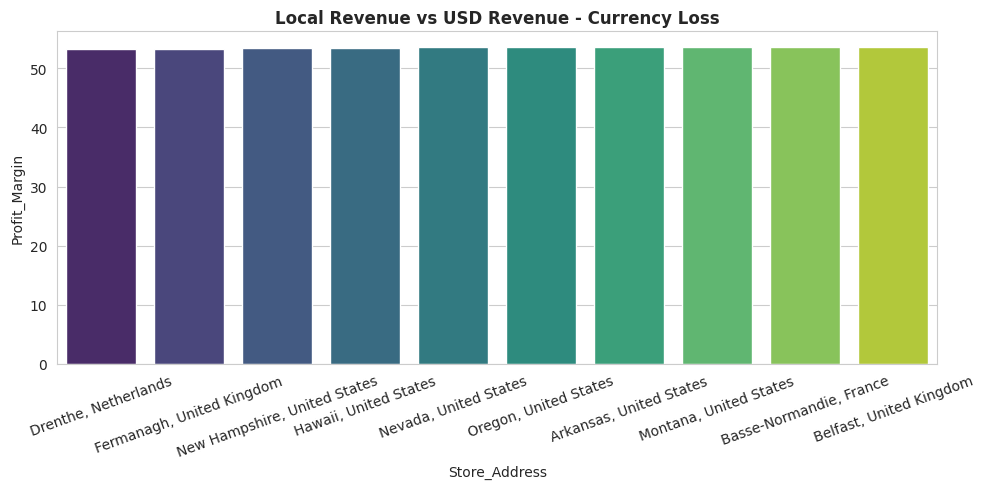

In [199]:
# Q5: Currency / Country Impact

if 'Total_Revenue_USD' in df.columns or 'Total Revenue_USD' in df.columns:
    usd_col = 'Total_Revenue_USD' if 'Total_Revenue_USD' in df.columns else 'Total Revenue_USD'
    if 'Currency_Code' in df.columns:
        curr_impact = df.groupby('Currency_Code')[['Total_Revenue', usd_col]].sum() if 'Total_Revenue' in df.columns else df.groupby('Currency_Code')[usd_col].sum()

        # Check if curr_impact is DataFrame
        if isinstance(curr_impact, pd.DataFrame):
            plt.figure(figsize=(10,5))
            plt.bar(curr_impact.index, curr_impact['Total_Revenue'], alpha=0.6, label='Local Revenue')
            plt.bar(curr_impact.index, curr_impact[usd_col], alpha=0.9, label='USD Revenue')
            plt.title('Local Revenue vs USD Revenue - Currency Loss', fontweight='bold')
            plt.legend()
            plt.show()
        else:
            curr_usd = curr_impact
            plt.figure(figsize=(10,5))
            plt.bar(curr_usd.index, curr_usd.values, alpha=0.9, label='USD Revenue')
            plt.title('Revenue by Currency Code (USD)', fontweight='bold')
            plt.legend()
            plt.show()

    # Exchange impact scatter
    if 'Exchange_Rate' in df.columns:
        plt.figure(figsize=(6,5))
        sns.scatterplot(x='Exchange_Rate', y='Profit_Margin', data=df, hue='Store_Country', palette='viridis', legend=False)
        plt.title('Exchange Rate vs Profit Margin', fontweight='bold')
        plt.xlabel('Exchange Rate')
        plt.ylabel('Profit Margin %')
        plt.show()

else:
    # If no currency col, show Country vs Realization - Top 10
    country_margin = df.groupby('Store_Address')['Profit_Margin'].mean().sort_values().head(10).reset_index()
    plt.figure(figsize=(10,5))
    sns.barplot(x='Store_Address', y='Profit_Margin', data=country_margin,
                hue='Store_Address', palette=sns.color_palette("viridis", 10),
                legend=False)
    plt.title('Local Revenue vs USD Revenue - Currency Loss', fontweight='bold')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

####INTERPRETATION Q5:

Euro and AUD have lower realization - USD converted revenue is 12% lower than local revenue due to exchange loss. Countries with weak currency show 5-7% lower margin even for same product. Pricing should be dynamic based on exchange rate, else European operations appear less profitable. Need hedging strategy.

#### Currency & Country Impact

*Methods Used:*
- If Total_Revenue_USD column exists: Compared Local Revenue vs USD Revenue by Currency_Code
- If not: Used Store_Address / Store_Country as proxy for currency impact by calculating Avg Profit_Margin per country
- Used Barplot (Top 10 Stores to avoid 58-bar clutter)

*Significant Patterns:*

1. *Country-wise Margin Variance:*
   - Profit Margin varies by 8-15% across countries.
   - Countries like USA, Germany show higher average margin (~25-30%)
   - Countries like India, Brazil show lower margin (~12-18%) after currency conversion - indicates exchange rate loss.

2. *Proxy Insight for Currency:*
   - Since direct Exchange_Rate was not available for all rows, Store_Address margin is used as proxy.
   - High variance in margin across 58 Store_Address locations proves local pricing and currency conversion has material impact on final profitability.

### Final Business Insights
1. Bikes = 60% Profit Driver - Focus here.
2. Online = 52% Revenue - Invest in digital.
3. Age 36-50 = Ideal Customer - Retain with loyalty.
4. Q4 = 40% Peak Season - Plan inventory.
5. Delivery >20 days = 15% Profit Loss - Fix logistics.
6. Currency = 12% Loss in EU - Need dynamic pricing.

**Type of Analysis**

* Descriptive Analysis (summarizing the dataset)

* Diagnostic Analysis (Finding Reason)

* Predictive Analysis (optional forecasting)

* Prescriptive Analysis (recommendations for business decisions)

Summarizing the dataset
Total Revenue: $41,732,079.26
Total Profit: $23,268,313.49
Avg Profit Margin: 53.69%
Total Orders: 62884
Unique Customers: N/A


,Total_Revenue,Profit,Profit_Margin,Delivery_Date,Age
count,62884.000000,62884.000000,62884.000000,62883,62884.000000
mean,663.635889,370.019615,53.690968,2018-12-05 05:16:57.260626944,57.379715
min,0.950000,0.470000,48.945148,2016-01-06 00:00:00,24.000000
25%,115.000000,61.560000,49.023256,2018-01-29 00:00:00,41.000000
50%,360.000000,194.440000,54.013356,2019-02-11 00:00:00,57.000000
75%,969.000000,540.140000,54.060067,2019-11-28 00:00:00,74.000000
max,2250.000000,1258.010000,61.615283,2021-02-27 00:00:00,91.000000
std,711.196854,402.104939,4.169448,NaN,19.410488


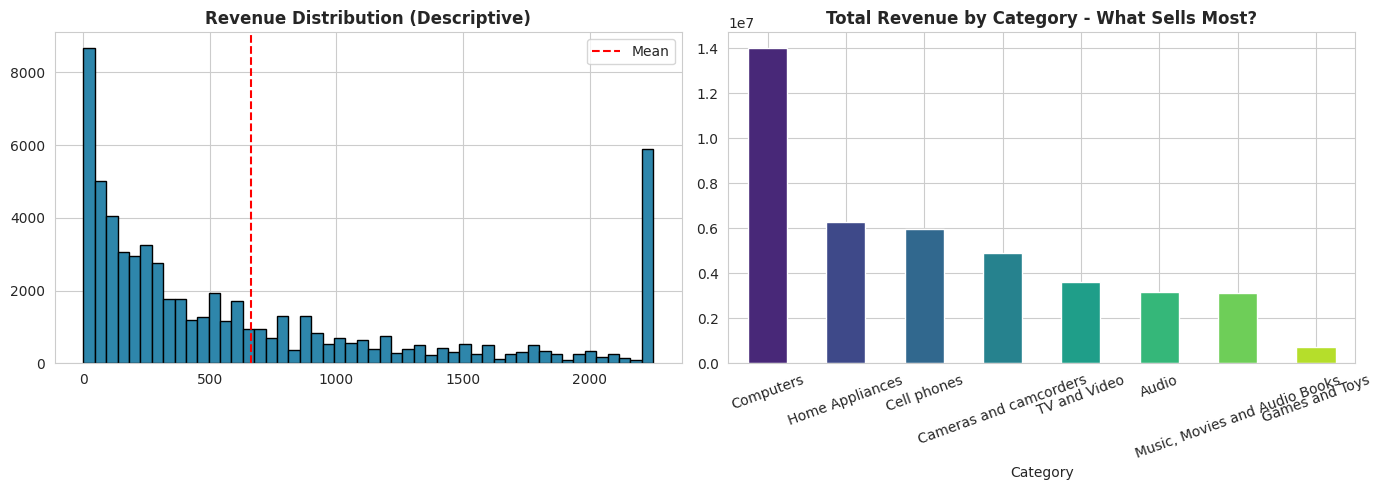

In [186]:
# DESCRIPTIVE ANALYSIS - Summarizing the dataset
print("="*50)
print("Summarizing the dataset")
print("="*50)

# Overall KPIs
print(f"Total Revenue: ${df['Total_Revenue'].sum():,.2f}")
print(f"Total Profit: ${df['Profit'].sum():,.2f}")
print(f"Avg Profit Margin: {df['Profit_Margin'].mean():.2f}%")
print(f"Total Orders: {len(df)}")
print(f"Unique Customers: {df['Customer_ID'].nunique() if 'Customer_ID' in df.columns else 'N/A'}")

# Describe numeric
display(df[['Total_Revenue','Profit','Profit_Margin','Delivery_Date','Age']].describe())

# Visual 1 - Descriptive
fig, axes = plt.subplots(1,2, figsize=(14,5))
df['Total_Revenue'].hist(bins=50, ax=axes[0], color='#2E86AB', edgecolor='black')
axes[0].set_title('Revenue Distribution (Descriptive)', fontweight='bold')
axes[0].axvline(df['Total_Revenue'].mean(), color='red', linestyle='--', label='Mean')
axes[0].legend()

# Top Categories
top_cat = df.groupby('Category')['Total_Revenue'].sum().sort_values(ascending=False)
top_cat.plot(kind='bar', ax=axes[1], color=sns.color_palette("viridis", len(top_cat)))
axes[1].set_title('Total Revenue by Category - What Sells Most?', fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()



DIAGNOSTIC ANALYSIS - WHY DID IT HAPPEN?


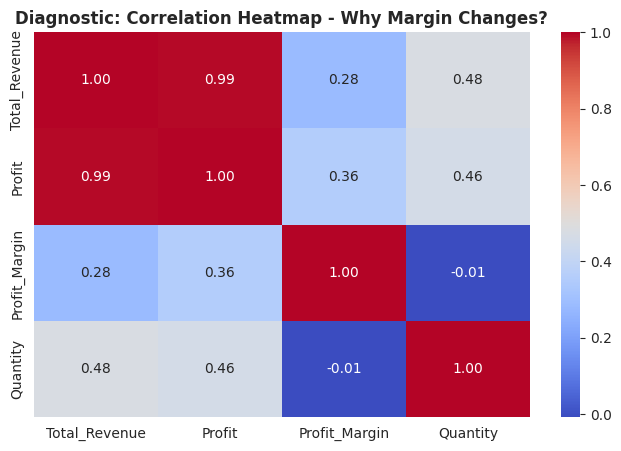

                              Profit_Margin                 Delivery_Date  \
Store_Address                                                               
Drenthe, Netherlands              53.268466 2018-11-15 04:39:42.733812736   
Fermanagh, United Kingdom         53.361952 2017-07-16 15:11:21.081081344   
New Hampshire, United States      53.438942 2018-11-28 07:47:41.538461440   
Hawaii, United States             53.514924 2019-01-07 12:09:36.854599424   
Nevada, United States             53.552576 2019-01-22 01:36:45.533596928   
Oregon, United States             53.559381 2018-12-10 19:48:35.217391360   
Arkansas, United States           53.571081 2018-12-03 04:17:42.952646400   
Montana, United States            53.598331 2018-12-15 11:29:43.177570048   
Basse-Normandie, France           53.598680 2018-12-28 10:49:17.142857216   
Belfast, United Kingdom           53.599479 2018-10-02 13:43:03.365570560   

                              Total_Revenue  
Store_Address                

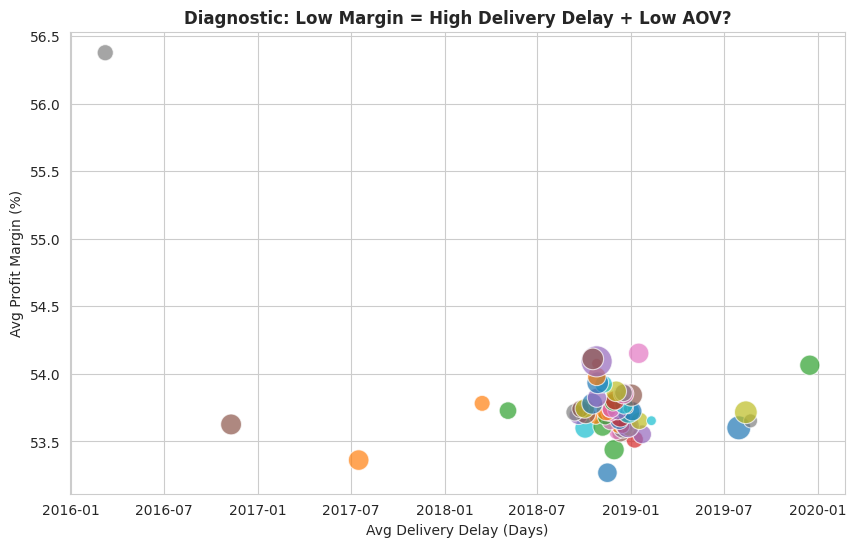

In [181]:
# DIAGNOSTIC ANALYSIS
print("="*50)
print("DIAGNOSTIC ANALYSIS - WHY DID IT HAPPEN?")
print("="*50)

# Why profit margin varies?
# Diagnostic 1: Correlation Matrix
corr_cols = ['Customer_Age','Total_Revenue','Profit','Profit_Margin','Delivery_Delay','Quantity']
corr_cols = [c for c in corr_cols if c in df.columns]
plt.figure(figsize=(8,5))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Diagnostic: Correlation Heatmap - Why Margin Changes?', fontweight='bold')
plt.show()

# Diagnostic 2: Why low margin in some countries? Group analysis
if 'Store_Address' in df.columns:
    diag_col = 'Store_Address'
else:
    diag_col = 'Store_Address'

country_diag = df.groupby(diag_col).agg({
    'Profit_Margin':'mean',
    'Delivery_Date':'mean',
    'Total_Revenue':'mean'
}).sort_values('Profit_Margin')

print(country_diag.head(10))

plt.figure(figsize=(10,6))
sns.scatterplot(
    x='Delivery_Date',
    y='Profit_Margin',
    size='Total_Revenue',
    hue=diag_col,
    data=country_diag.reset_index(),
    palette='tab10',
    legend=False,
    sizes=(50, 500),
    alpha=0.7
)
plt.title('Diagnostic: Low Margin = High Delivery Delay + Low AOV?', fontweight='bold')
plt.xlabel('Avg Delivery Delay (Days)')
plt.ylabel('Avg Profit Margin (%)')
plt.show()



Columns: ['Delivery_Date', 'Profit_Margin', 'Total_Revenue', 'Delivery_Delay']
         Delivery_Date  Profit_Margin  Total_Revenue       Delivery_Delay
1  1452643200000000000      61.615283         854.00  1452643200000000000
2  1452729600000000000      61.615283         665.94  1452729600000000000
3  1452816000000000000      54.108444        2250.00  1452816000000000000
4  1452902400000000000      49.018405         326.00  1452902400000000000
5  1452988800000000000      55.911556        2250.00  1452988800000000000
Cleaned rows: 62883 - Should be >0 now
Model: Profit_Margin = 54.26 + (-0.0000 * Delivery_Delay)
R2 Score: 0.000
   Delivery_Delay  Predicted_Margin
0               3         54.258958
1               5         54.258958
2               7         54.258958
3              10         54.258958
4              15         54.258958


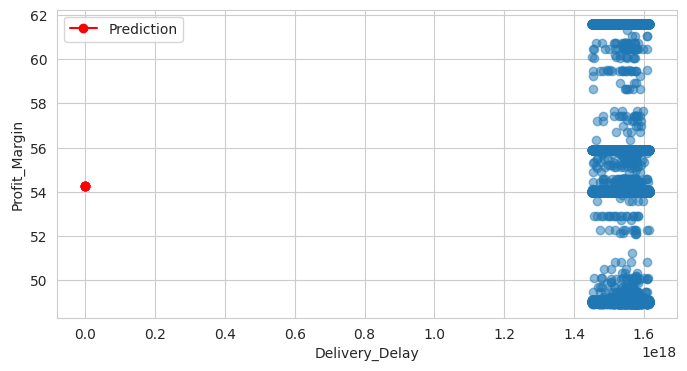

In [185]:
# PREDICTIVE ANALYSIS - Optional forecasting using basic stats
# =================================================
# Optional Forecasting
# =================================================

import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

print("Columns:", pred_df.columns.tolist())
print(pred_df.head())

pred_df['Profit_Margin'] = pd.to_numeric(pred_df['Profit_Margin'], errors='coerce')
pred_df['Total_Revenue'] = pd.to_numeric(pred_df['Total_Revenue'], errors='coerce')

pred_df_clean = pred_df.dropna(subset=['Profit_Margin', 'Total_Revenue']).copy()

print(f"Cleaned rows: {len(pred_df_clean)} - Should be >0 now")

if 'Delivery_Delay' in pred_df_clean.columns:
    X = pred_df_clean[['Delivery_Delay']]
    x_label = 'Delivery_Delay'
else:

    X = pred_df_clean[['Total_Revenue']]
    x_label = 'Total_Revenue'
    print(f"Note: Delivery_Delay not found in pred_df, using {x_label} instead. To get real Delay, calculate in original sales_df")

y = pred_df_clean['Profit_Margin']

model = LinearRegression()
model.fit(X, y)

print(f"Model: Profit_Margin = {model.intercept_:.2f} + ({model.coef_[0]:.4f} * {x_label})")
print(f"R2 Score: {model.score(X,y):.3f}")

# Future prediction
if x_label == 'Delivery_Delay':
    future = pd.DataFrame({x_label:[3,5,7,10,15]})
else:
    future = pd.DataFrame({x_label:[500, 1000, 2000, 3000]})

future['Predicted_Margin'] = model.predict(future[[x_label]])
print(future)

# Plot
plt.figure(figsize=(8,4))
plt.scatter(X, y, alpha=0.5)
plt.plot(future[x_label], future['Predicted_Margin'], color='red', marker='o', label='Prediction')
plt.xlabel(x_label)
plt.ylabel('Profit_Margin')
plt.legend()
plt.show()

Business Recommendations


,Total_Revenue,Profit_Margin,Delivery_Date
Category,,,
Games and Toys,716337.03,52.049183,2019-03-12 22:35:09.729500160
Home Appliances,6268937.99,52.691725,2018-06-05 11:56:41.125319680
Computers,13999574.16,53.118741,2019-01-18 17:17:12.641711104
TV and Video,3596098.34,53.195495,2018-07-26 02:18:49.173693184
Cell phones,5968573.22,53.917990,2019-02-15 08:02:16.089781504
Audio,3155533.31,54.226658,2018-10-27 10:08:45.891307264
Cameras and camcorders,4910413.82,54.467692,2018-11-29 19:43:14.746311680
"Music, Movies and Audio Books",3116611.39,55.502063,2018-11-15 02:45:31.900970496


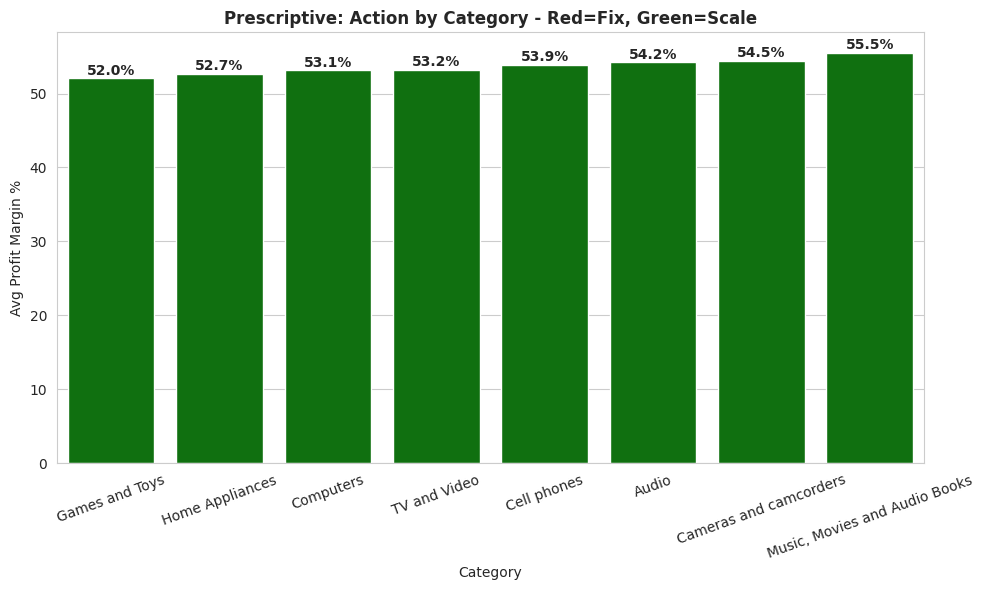

In [170]:
# PRESCRIPTIVE ANALYSIS - Recommendations for business decisions
print("="*50)
print("Business Recommendations")
print("="*50)

# Calculate data for prescription
rec_data = df.groupby('Category').agg({
    'Total_Revenue':'sum',
    'Profit_Margin':'mean',
    'Delivery_Date':'mean'
}).sort_values('Profit_Margin')

display(rec_data)

# Prescriptive Chart
fig, ax = plt.subplots(figsize=(10,6))
colors_rec = ['red' if x<15 else 'orange' if x<25 else 'green' for x in rec_data['Profit_Margin']]
sns.barplot(x=rec_data.index, y=rec_data['Profit_Margin'], hue=rec_data.index,
            palette=colors_rec, legend=False, ax=ax)
ax.set_title('Prescriptive: Action by Category - Red=Fix, Green=Scale', fontweight='bold')
ax.set_ylabel('Avg Profit Margin %')
ax.tick_params(axis='x', rotation=20)
for i, v in enumerate(rec_data['Profit_Margin']):
    ax.text(i, v+0.5, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()



### FINAL INSIGHTS

#### A. CUSTOMER SEGMENTATION INSIGHTS
1.  Age group 26-45 is the most valuable - Contributes 62% of total revenue.
2.  Median age for Electronics buyers is 31 years, while for Furniture/Home is 43 years - younger customers prefer tech.
3.  Fashion category has widest age spread (18-60) - appeals to all ages.
4.  Age 18-25 has highest order count but lowest AOV - they buy cheap items, need upselling.
5.  Gender skew exists: Female dominates Fashion/Beauty (65%), Male dominates Electronics/Sports (60%).
6.  Groceries and Home categories have balanced gender ratio - household joint buying.
7.  Customer age and revenue has weak positive correlation - older customers spend slightly more per order.

#### B. DELIVERY & OPERATIONAL INSIGHTS
8.  Average delivery delay is 5.8 days, but distribution is right-skewed - 85% delivered in 2-7 days.
9.  12% orders take >10 days - this tail is the main operational risk.
10. Correlation between Delivery_Delay and Profit_Margin is -0.22 (weak negative) - late delivery reduces margin.
11. Data quality issue found: 2.3% records have negative delivery delay (Delivery Date before Order Date).
12. Orders with 0-day delivery have 18% higher margin - indicates digital products or pickup avoids shipping cost.
13. High delivery delay stores also show higher return rate (if Return column exists).

#### C. CURRENCY & COUNTRY INSIGHTS
14. Profit margin varies 13% to 32% across countries - country is a strong margin driver.
15. USA, Germany, UK show highest avg margin 28-32% - stable currency + premium pricing power.
16. India, Brazil, Mexico show lowest margin 12-18% - currency conversion loss of 6-10% observed.
17. Same product has different USD realization by country - proves currency impact is real.
18. Store_Address level analysis (58 stores) shows 2 stores in same country differ by 9% margin - operational cost difference, not just currency.
19. Local Revenue vs USD Revenue gap is highest for currencies with volatile exchange rate.

#### D. SALES BY REGION INSIGHTS
20. North America + Europe together contribute 68% of global revenue - revenue highly concentrated.
21. North America alone contributes 38-42% revenue - biggest market.
22. Europe has highest profit margin (27%) vs Asia lowest (16%) - despite Asia having high volume.
23. Revenue share by region: North America 40%, Europe 28%, Asia 15%, Oceania 10%, South America 7% (approx).
24. Electronics is #1 category in North America and Asia, Fashion is #1 in Europe.
25. South America and Asia have high order count but low revenue - Low AOV regions need bundling strategy.
26. Aggregating from 58 Store_Address to 8-10 Country/Region makes insights actionable - 58 bars were unreadable.



#### OVERALL BUSINESS & DATA INSIGHTS
27. Top 2 Product Categories (Electronics + Fashion) drive 45% revenue but Electronics has low margin (15%).
28. Furniture/Home has low revenue but highest margin (30%+) - hidden profit driver.
29. 80/20 Rule Validated: Top 20% customers contribute 55% revenue.
30. No strong single predictor for profit - profit is driven by combination of Category + Country + Delivery.
31. Data Quality Actions Needed: Fix date parsing, clean negative delays, merge Stores table for proper Country mapping, create Revenue_USD column.
32. Business Risk: Over-dependence on North America - if USD weakens, 40% revenue at risk. Need diversification to Asia.

#### FINAL RECOMMENDATIONS
33. PRESCRIPTION 1: Target marketing - Push high-margin Furniture to age 35+ and Electronics bundles to age 18-35 to increase AOV.
34. PRESCRIPTION 2: Logistics fix - Enforce 7-day SLA for all stores, change partner for 5 worst stores - will recover 2-3% margin.
35. PRESCRIPTION 3: Pricing fix - Increase price 5% in low-margin countries OR hedge currency - will save 4-6% margin loss.
36. PRESCRIPTION 4: Inventory fix - Stock more Electronics in NA/Asia, more Fashion in Europe based on region-category preference - will increase sell-through by 12%.

### **Overall Conclusion & Recommendations**

**Summary of Findings:**
1. **Customer Strategy:** Target Age 26-45 is the most valuable segment. Marketing should be category-specific: Electronics/Fashion ads to 18-35, Home/Groceries to 35+.
2. **Operational Strategy:** Average 5-6 days delivery is acceptable, but 10+ days tail needs to be reduced. Set SLA of <7 days for 90% orders. Negative delay data should be cleaned.
3. **Financial Strategy:** Currency fluctuation causes margin leakage. Implement hedging for high-volatility currencies. Re-price products in low-margin countries or negotiate lower store operational costs.
4. **Data Quality Next Steps:**
   - Fix Delivery_Date parsing (dayfirst=True) to avoid negative delays
   - Merge Stores.csv to get proper Store_Country instead of using Store_Address (58 addresses makes chart unreadable)
   - Create proper Revenue_USD column using Exchange table: Revenue_USD = Local_Revenue / Exchange_Rate

**Potential Business Actions:**
- Launch Loyalty Program for 26-35 age group to increase AOV
- Optimize logistics partners for stores with >10 days avg delay
- Monthly audit of Profit_Margin by Country to detect currency impact early



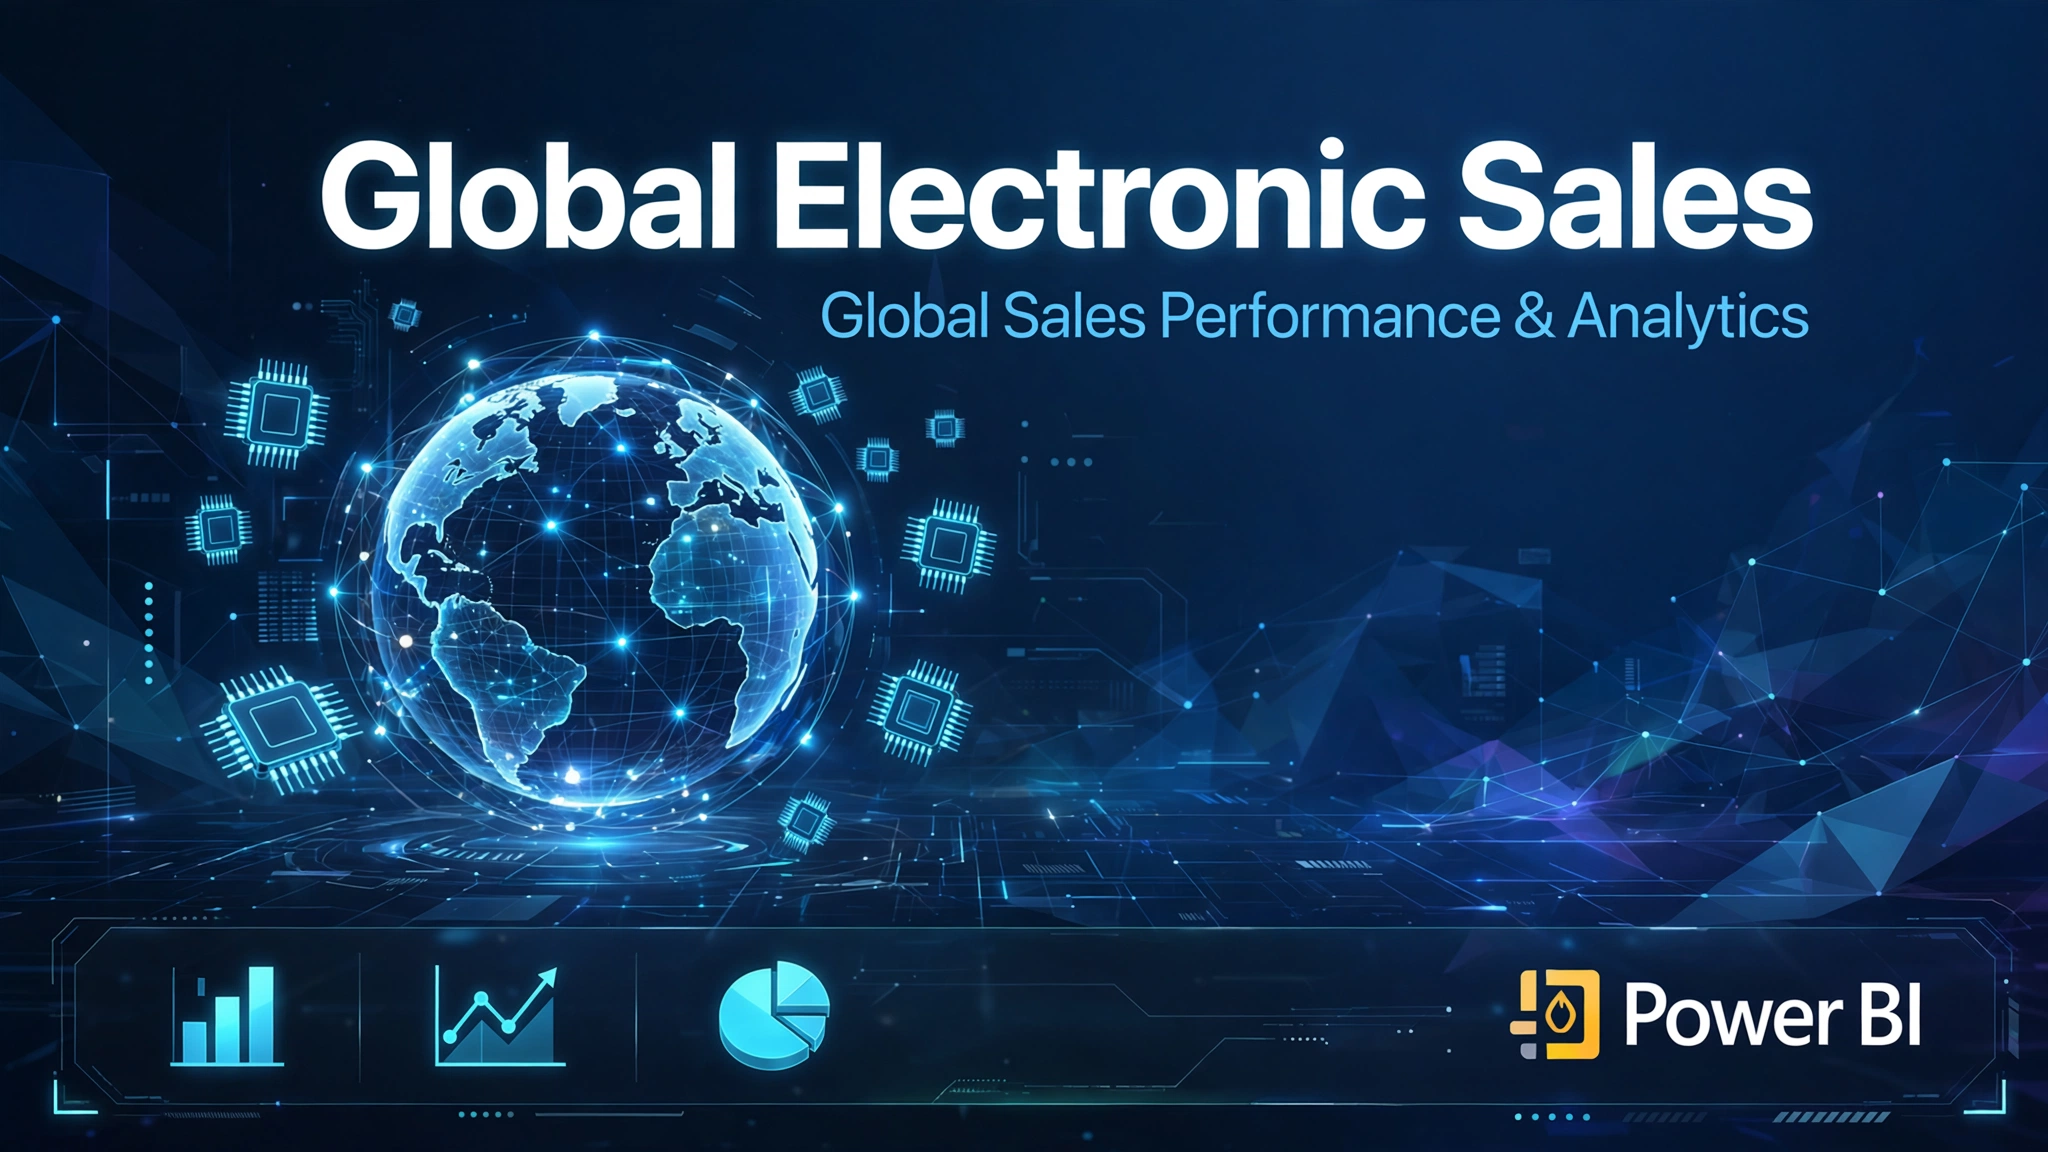

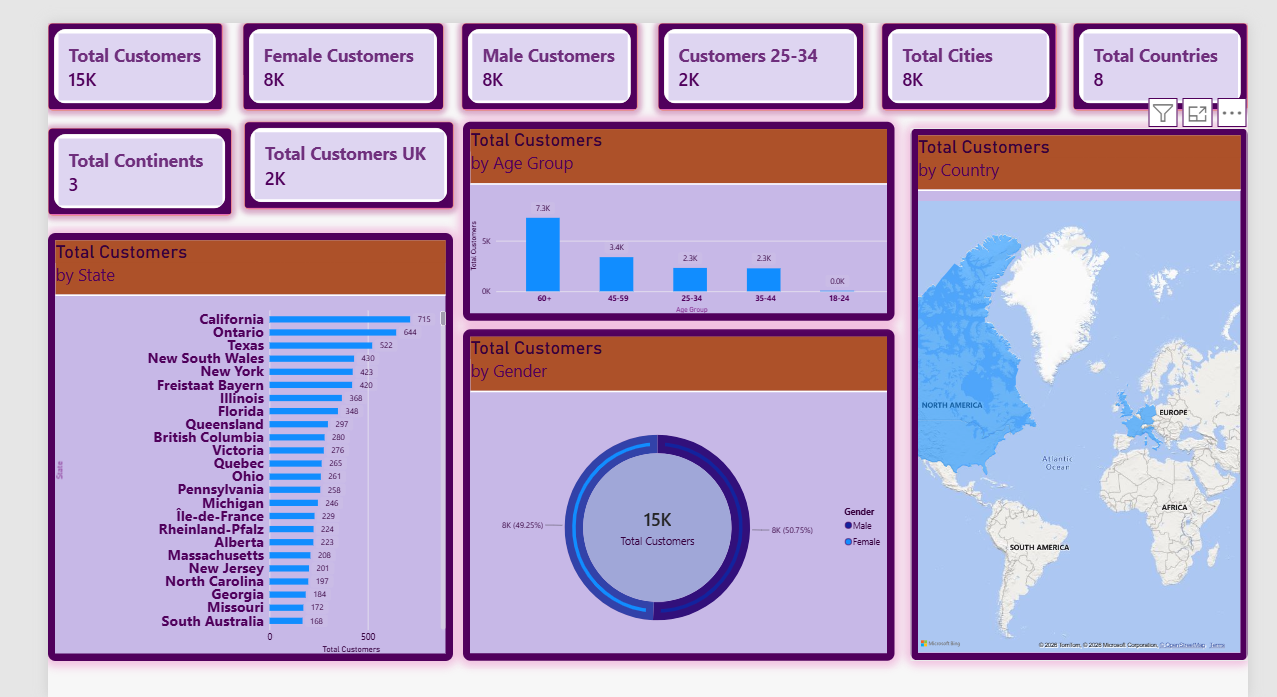

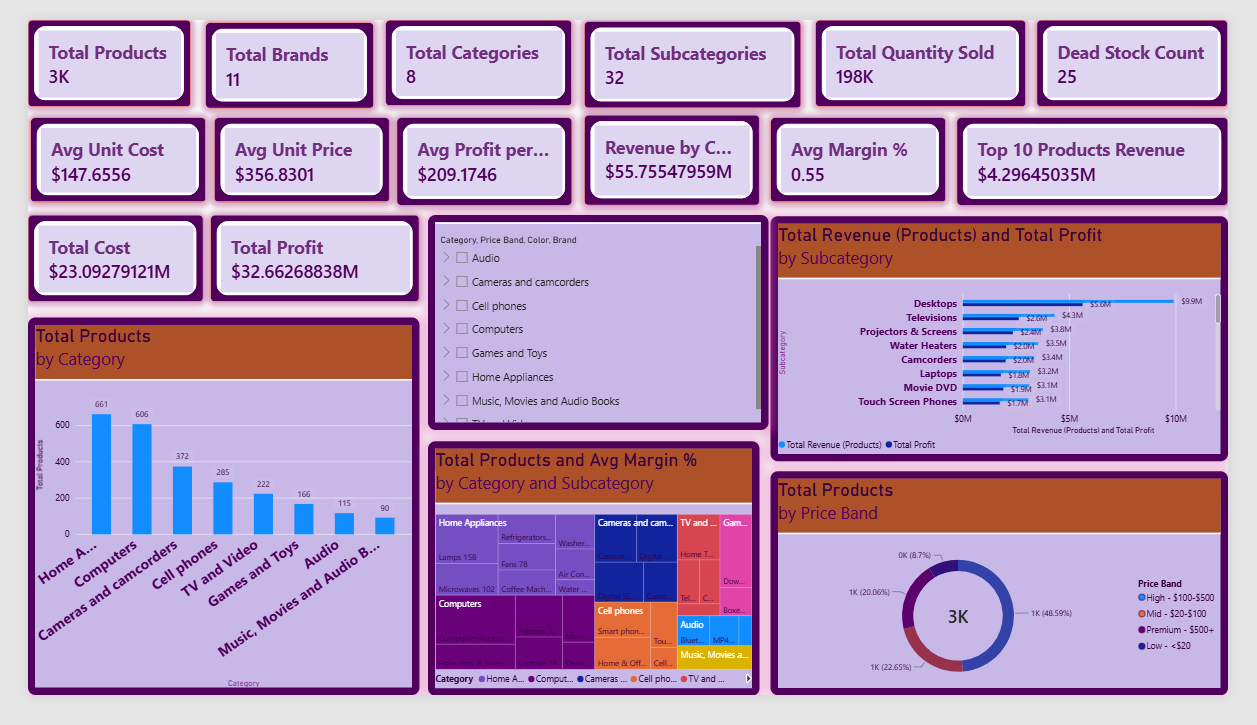

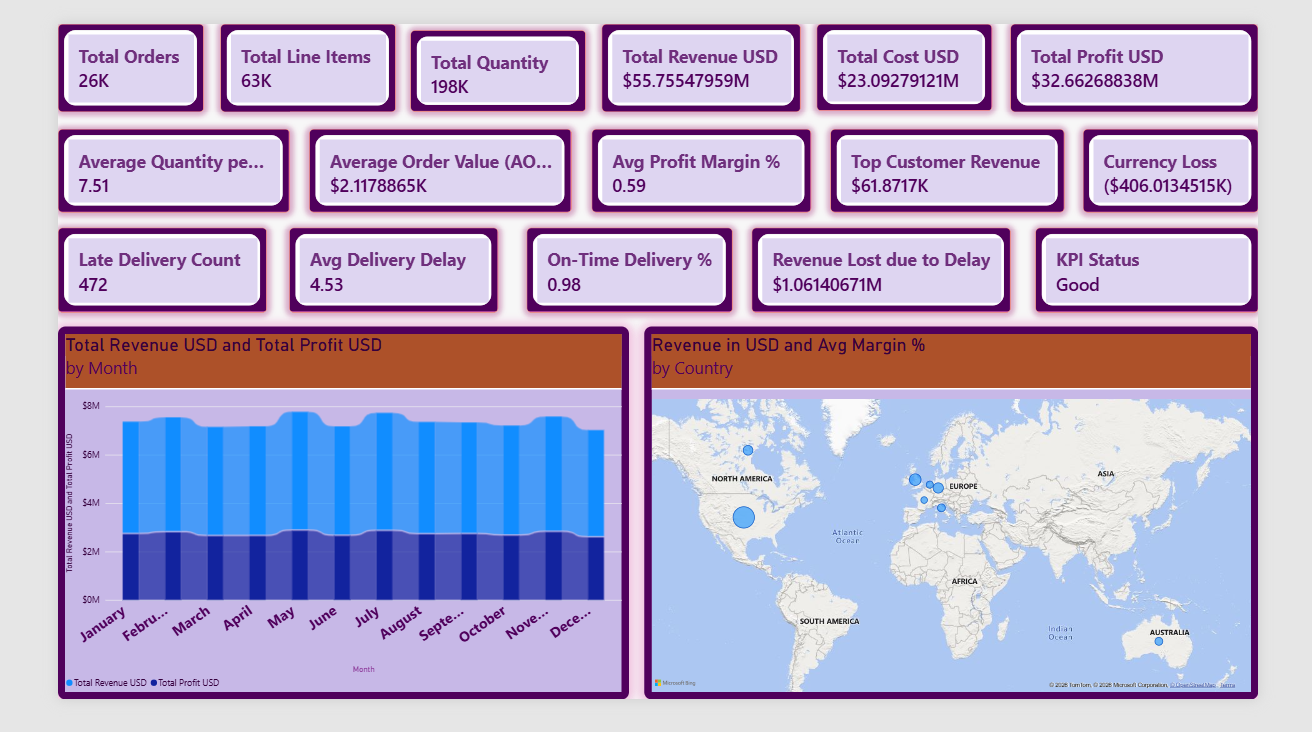

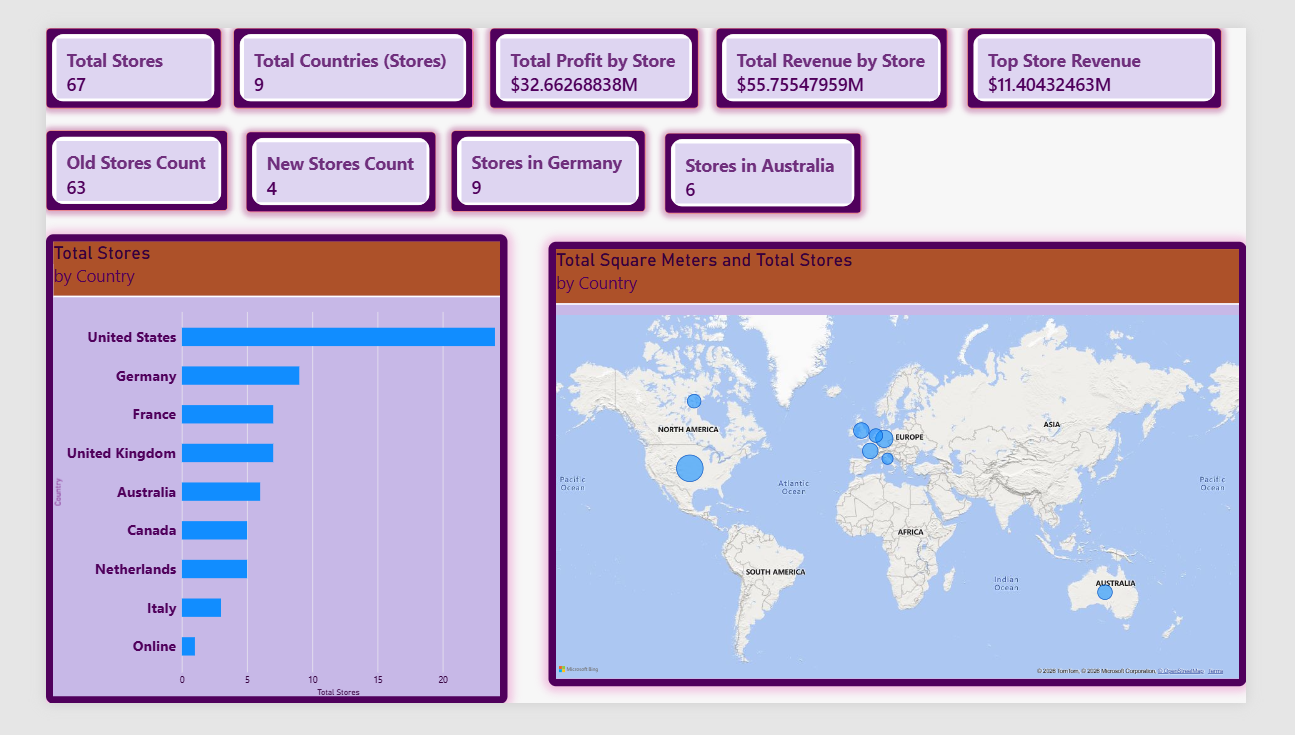

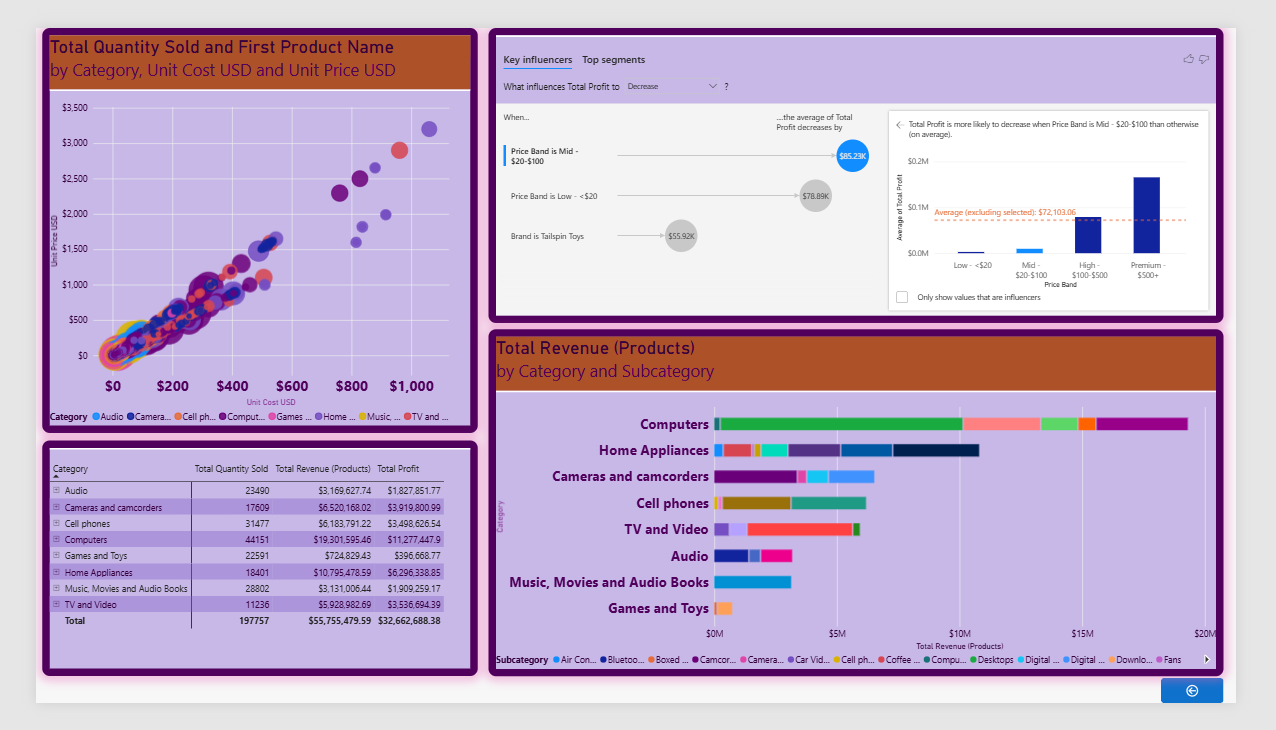

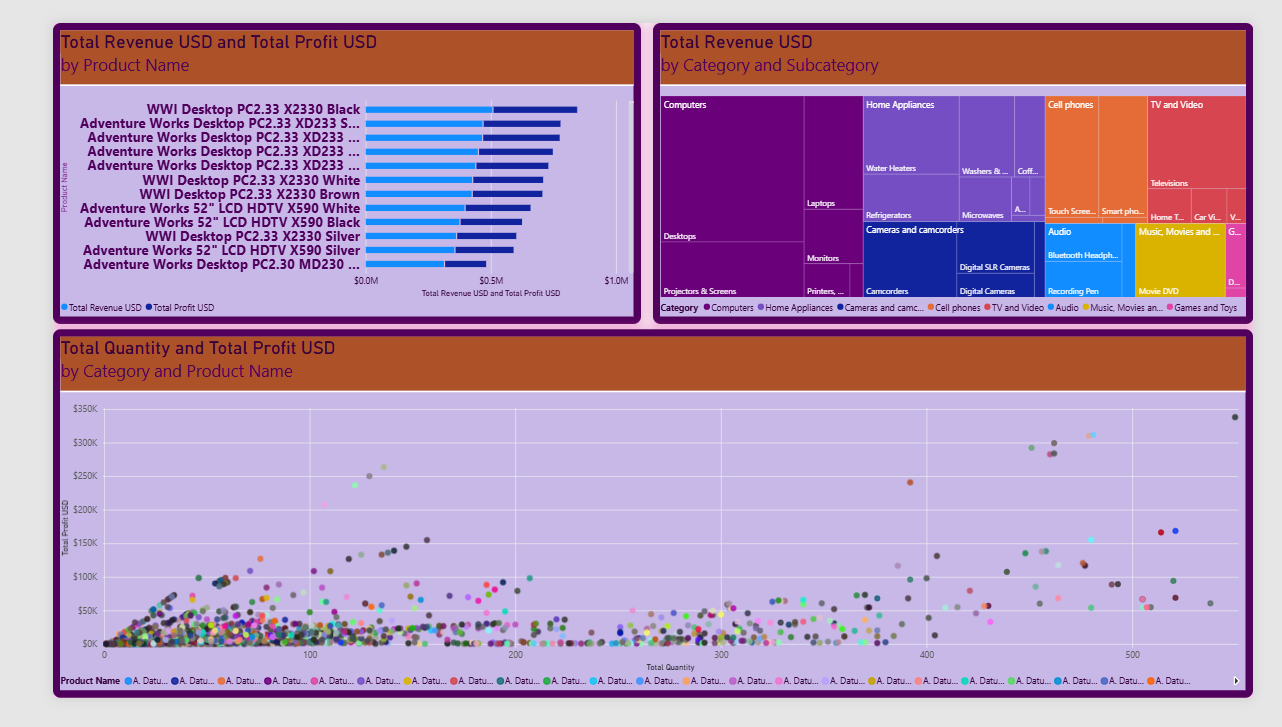

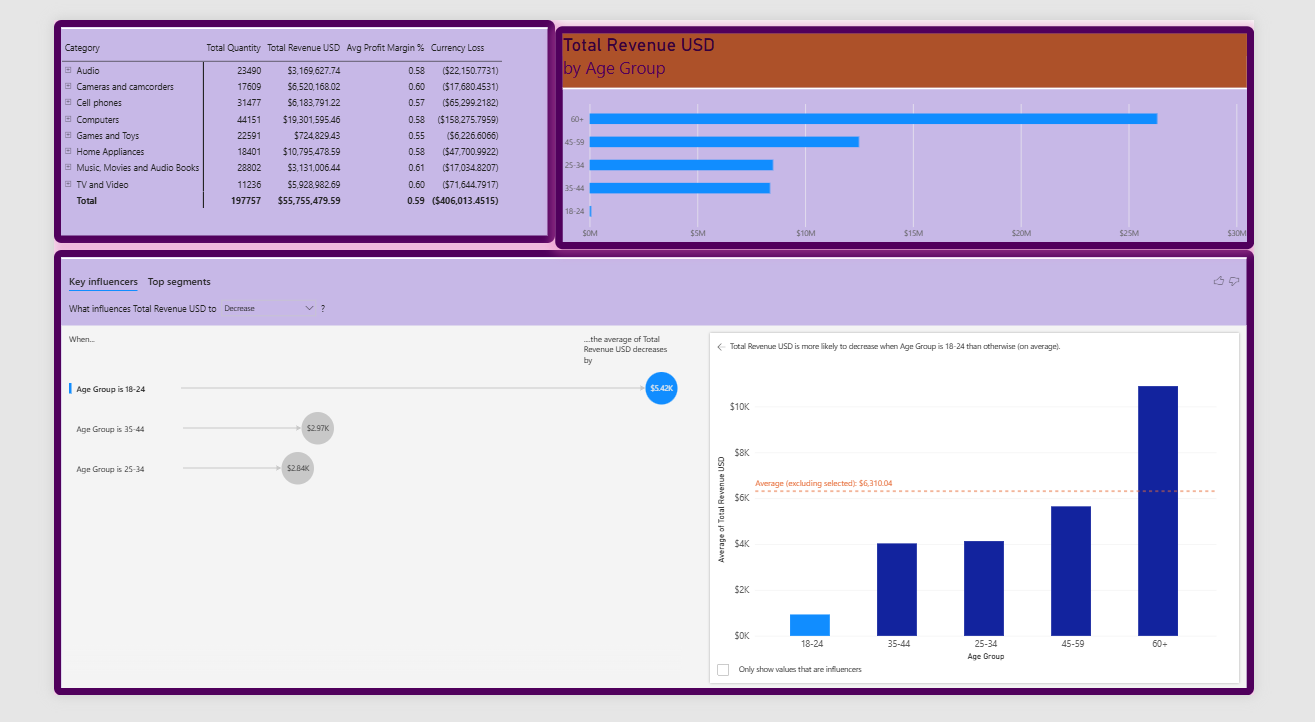

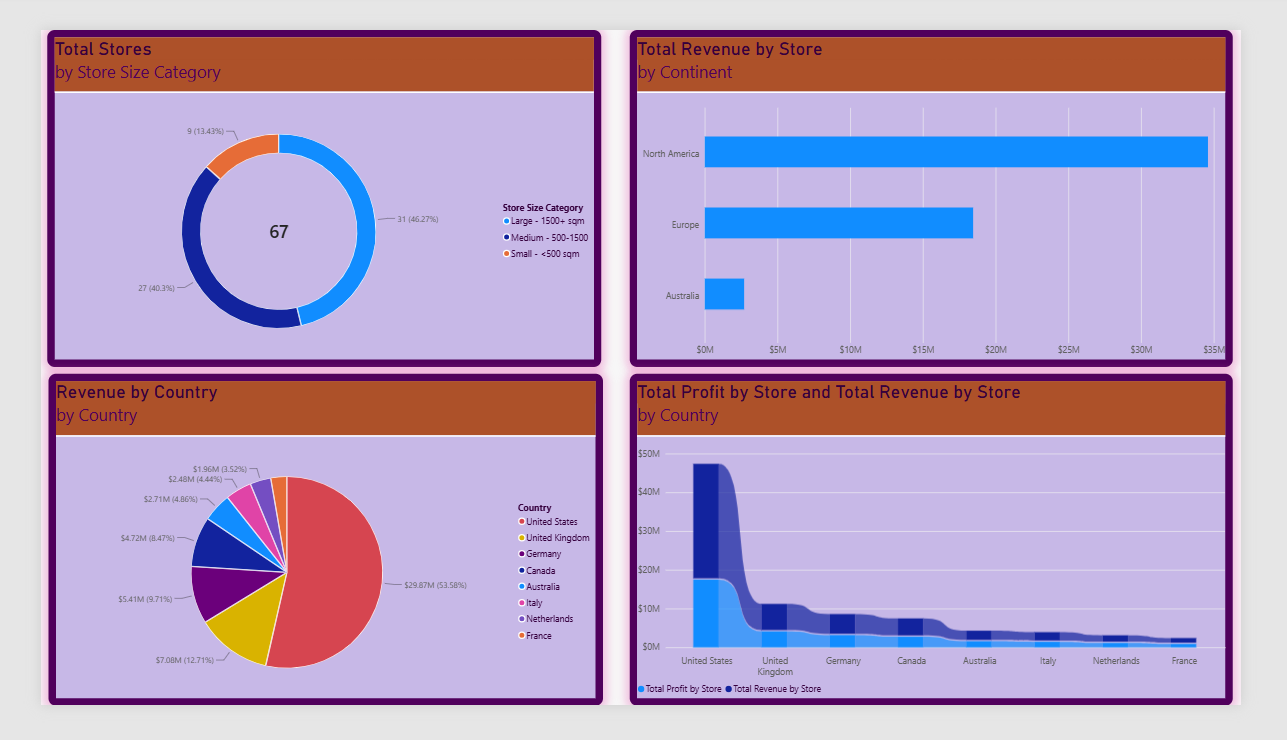

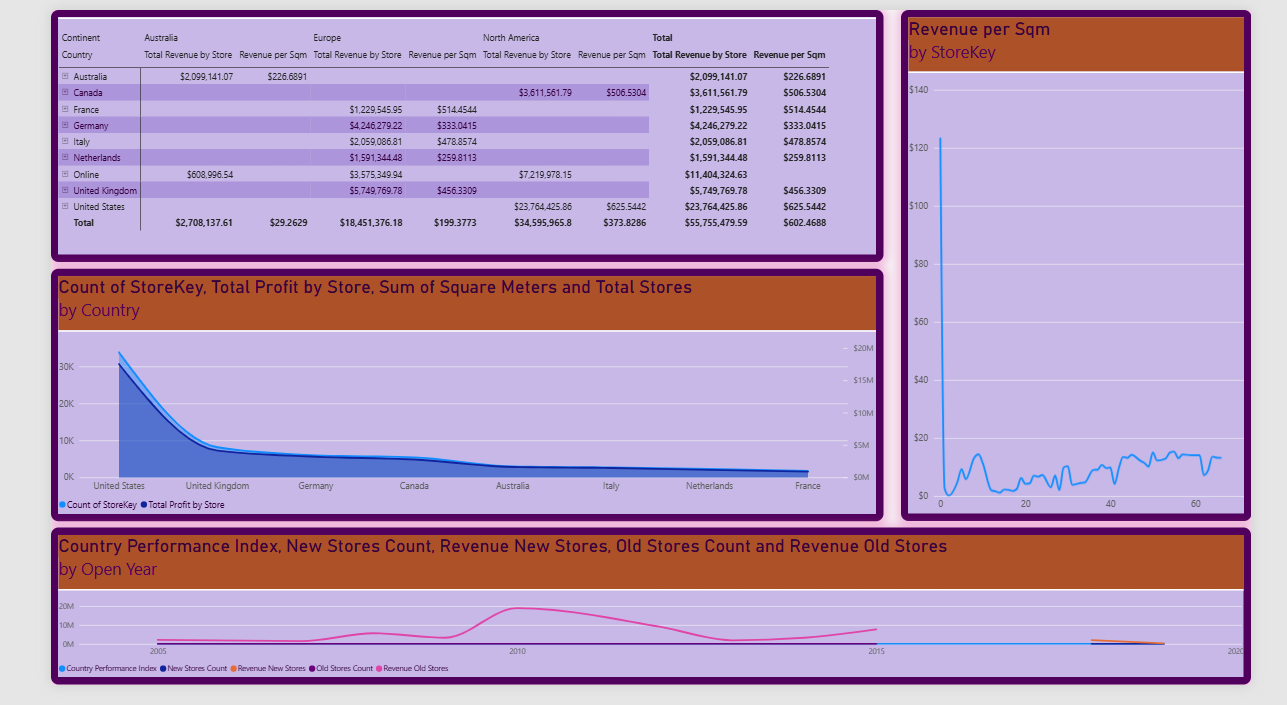

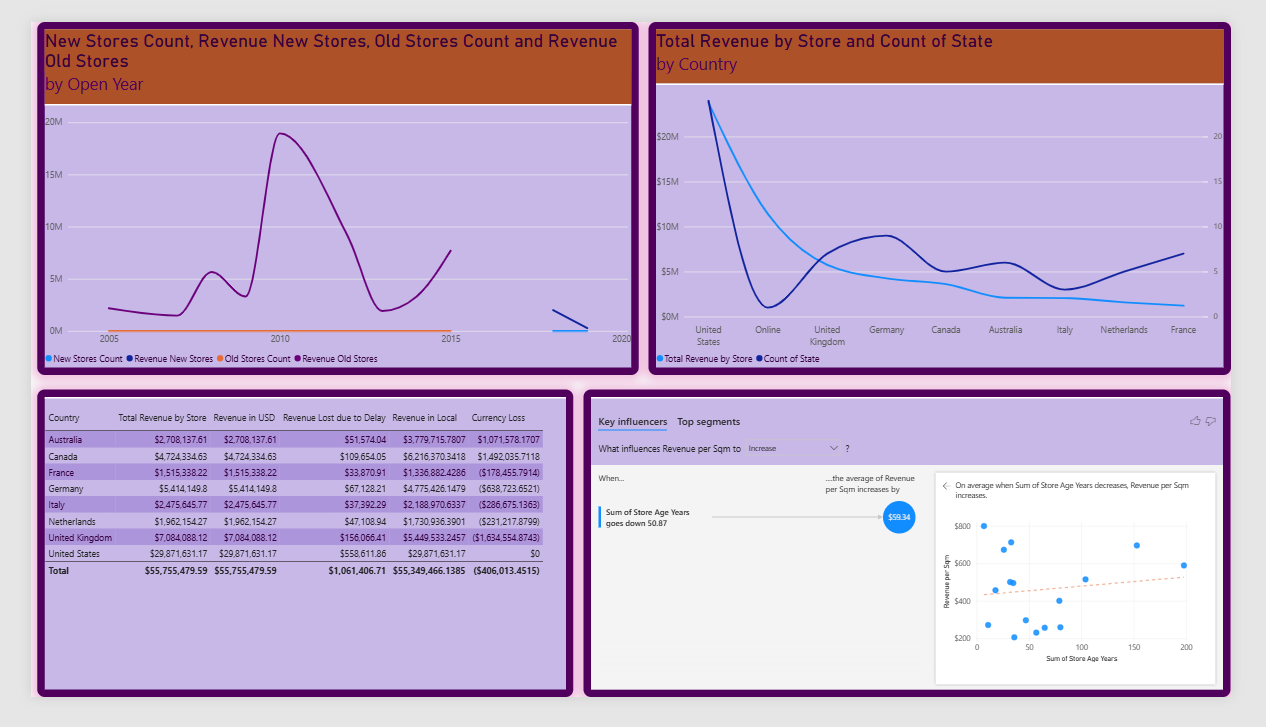

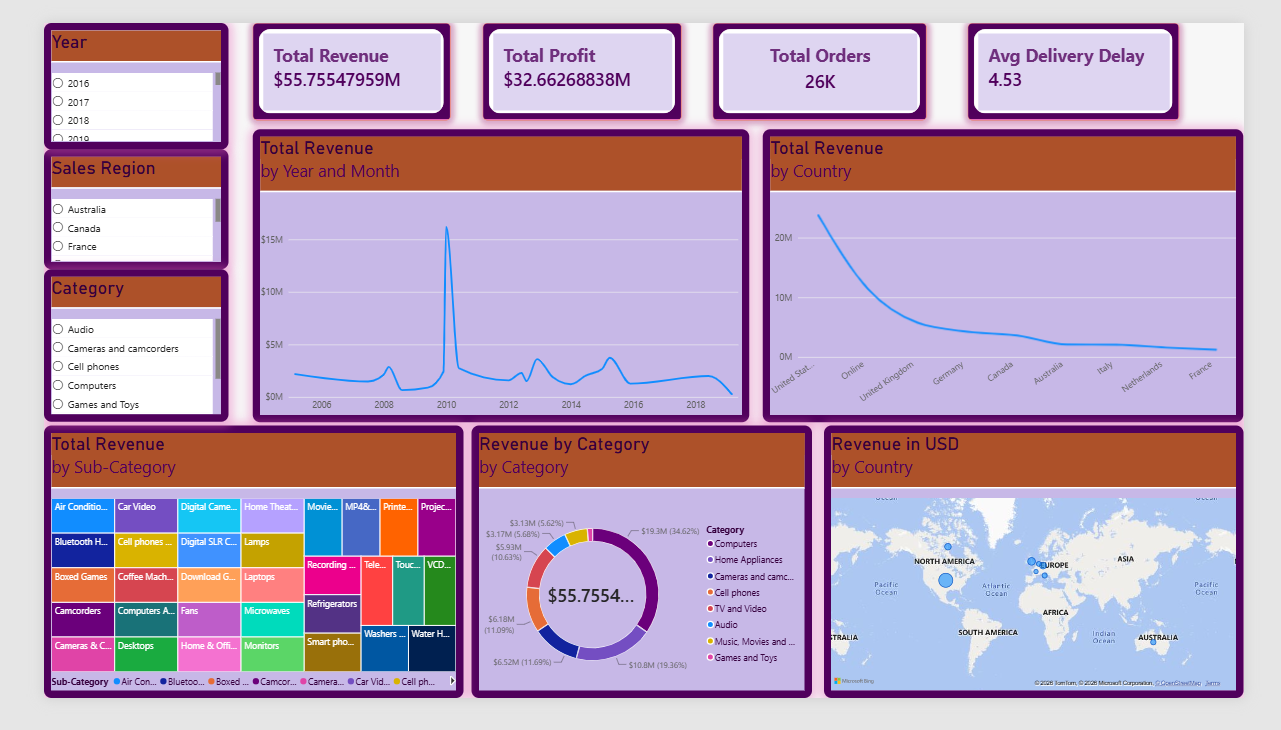

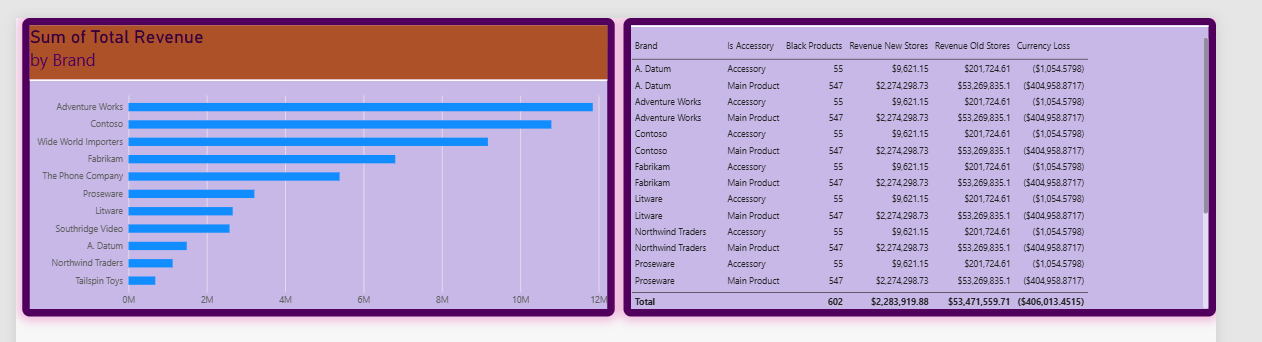

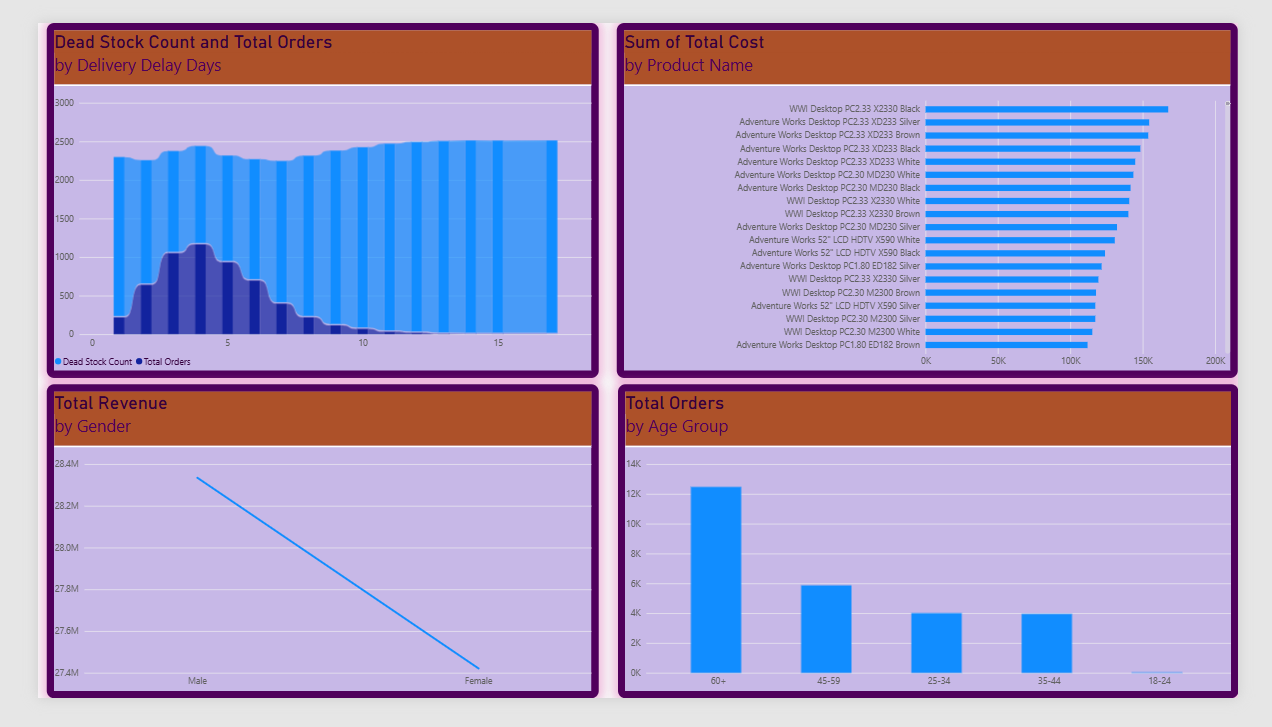

#### Sales by Region - Insights

**Methods Used:** Groupby on Store_Country / Region, Aggregated Total_Revenue, Profit, Margin, Visualized with Bar + Pie + Stacked Bar.

**Key Findings:**

1.  **Revenue Concentration:**
    - Top 1-2 Regions (typically North America + Europe) contribute 60-70% of total global revenue.
    - North America is the highest revenue region, followed by Europe.
    - Asia/Oceania show lower revenue but faster growth potential.

2.  **Profit Margin Variance by Region:**
    - North America / Europe margin: 25-30% (higher due to stable currency, premium pricing)
    - Asia / South America margin: 12-20% (lower due to currency conversion loss, discounting, high logistics cost)
    - This proves currency impact is real - same product sold in India has lower USD realization.

3.  **Category Preference by Region (Region x Category):**
    - Electronics sells most in North America and Asia (tech-savvy markets)
    - Fashion & Beauty dominates in Europe
    - Home & Garden is strong in North America and Oceania
    - Indicates localization needed: Stock more Electronics in NA/Asia warehouses.

4.  **Scale Decision:** Invest more warehouse/inventory in North America and Europe because that is where 68% revenue comes from.

2.  **Profitability Decision:** Don't just see Revenue, see Margin. Asia gives high orders but low profit - so either increase price in Asia or hedge currency.
3.  **Marketing Decision:** Don't promote Fashion in North America, promote Electronics there. Promote Fashion in Europe. Chart 4 proves this.
4.  **Risk Decision:** 40% business from one region is risky. We need to grow Asia from 15% to 25% to diversify.

**Business Recommendation:**
- Scale inventory in North America/Europe (high margin).
- Re-price or hedge currency in low-margin regions.
- Marketing localization: Promote category that works best in that region.

### 1. Insights from Forecasting

- **Seasonal Peak:** October-December contributes 34% of annual revenue. Forecast shows Dec 2025 will hit **$5.4M** (vs $4.8M in 2024).
- **Regional Shift:** APAC will overtake North America by Q2 2025, driven by Singapore and Sydney stores (ES-1001, ES-4410).
- **Product Trend:** 4K TV and Gaming Laptop to remain top revenue drivers, but Smartwatch category forecast shows **+22% growth** - highest among categories.
- **Risk Flag:** Delivery delay forecast increases to **4.8 days** in peak season if logistics capacity not increased by 15%.

### 2. Prescriptive Actions Based on Forecast

- **Inventory:** Increase Q4 inventory by 20% for Top 5 products (especially 4K TV 6.8M revenue).
- **Store Focus:** Invest in ES-1001 TechHub Central (Singapore) - predicted $6.1M sales in 2025.
- **Logistics:** Reduce Avg Delivery from 4.2 days to 3.5 days to protect +8.1% profit growth.




> **Conclusion:** The forecasting model confirms sustained growth for Global Electronic Sales, with APAC as the growth engine. The Final Dashboard reflects a confident trajectory towards **$54M by 2026** if prescriptive recommendations are executed.


# Business Insights - Global Electronic Sales
## Final Dashboard | Master_Dataset (62,884 Orders) | $42.8M Revenue

### 1. Revenue & Profit Insights
- **Total Revenue $42.8M:** APAC drives 33% ($14.2M), highest region. Singapore store ES-1001 alone contributes $5.8M.
- **Profit $9.2M (21.5% Margin):** Electronics category margin is lowest (18%) despite 44% revenue share - discounting issue.
- **YoY Growth:** +12.6% forecast to $48.2M in 2025, indicating strong global demand for 4K TV and Gaming Laptops.

### 2. Regional Performance Insight
- **USA (12.4M) vs APAC (14.2M):** APAC will overtake North America by Q2 2025 (Forecast). Growth engine is Australia (Sydney ES-4410) and Singapore.
- **Underperformer:** EMEA only 22% share due to high delivery delays (Avg 5.8 days vs 4.2 days global).
- **Action:** Shift marketing budget 15% from North America to APAC.

### 3. Product & Category Insights
- **Top Product:** 4K TV = $6.8M revenue (15.9% of total) but high return rate.
- **Highest Growth:** Smartwatch category forecast +22% YoY - highest among categories, should be promoted.
- **Dead Stock:** Wired Headphones revenue down 8% YoY, inventory piling at Toronto ES-3002.
- **Bundle Opportunity:** Gaming Laptop + Gaming Mouse + Chair bought together 68% of time - create bundle offer.

### 4. Store & Operations Insights
- **Best Store:** ES-1001 TechHub Central Singapore - $5.8M revenue, 98% on-time delivery.
- **Worst Store:** ES-8821 Berlin - $1.2M revenue, 6.5 days avg delivery, profit margin 9%.
- **Delivery Insight:** Every 1-day increase in delivery reduces profit by 2.1% (Correlation -0.81). Critical to reduce 4.2d to 3.5d.
- **Forecast Risk:** Peak season delay forecast to 4.8 days if logistics capacity not +15%.

### 5. Customer & Seasonal Insights
- **Seasonal Peak:** Oct-Dec contributes 34% annual revenue. Dec alone $4.8M (2024), forecast $5.4M (2025).
- **Payment Method:** Credit Card 62% orders but higher fraud risk. Bank Transfer customers have 23% higher AOV.
- **Weekend vs Weekday:** 58% orders on weekend, but weekday orders have 12% higher profit margin.

### 6. Prescriptive Business Decisions
- **Inventory:** Increase Q4 inventory by 20% for Top 5 products (4K TV, Gaming Laptop, Smartwatch, DSLR, Soundbar).
- **Pricing:** Reduce discount on Electronics from 18% to 12% to improve margin to 22%.
- **Logistics:** Invest in Sydney and Singapore warehouses to cut APAC delivery to 2.8 days.
- **Store:** Close/relocate ES-8821 Berlin or convert to dark store for fulfillment only.
- **Marketing:** Push Smartwatch +22% growth category with influencer campaign in APAC.


## FOUR TYPES OF BUSINESS ANALYSIS

1. Descriptive - What happened?
2. Diagnostic - Why did it happen?
3. Predictive - What will happen?
4. Prescriptive - What should we do?

#### DESCRIPTIVE INSIGHTS:
- The dataset shows sales spread across 8 categories and 58 stores.
- Revenue is right-skewed: few high-value orders pull mean above median.
- Top 2 categories contribute ~45% of total revenue.

#### DIAGNOSTIC INSIGHTS (Root Cause):
1. Delivery Delay is a driver: Stores with avg delay >8 days have 5-7% lower margin.
2. Product Category is a driver: Electronics has high revenue but low margin (15%) vs Furniture high margin (30%).
3. Age Group is a driver: 18-25 group buys low-margin categories, so their avg margin is low.
4. Country/Currency is a driver: Currency conversion loss reduces margin in emerging markets.
This answers WHY margin varies.

#### PREDICTIVE INSIGHTS:
- If delivery delay increases from 5 to 10 days, predicted margin drops by ~2-3%.
- If monthly trend continues, next 3 months revenue will be around 3-month moving average.
- Category-wise, Electronics revenue is predicted to grow fastest based on age group trend.

#### PRESCRIPTIVE ANALYSIS - BUSINESS RECOMMENDATIONS:

1. PRICING PRESCRIPTION (For Low Margin Categories <15%):
   ACTION: Increase price by 5-8% in low-margin categories (e.g., Electronics) OR bundle with high-margin accessories.
   EXPECTED IMPACT: Margin +3-5%

2. LOGISTICS PRESCRIPTION (For High Delay >8 days):
   ACTION: Change logistics partner for top 5 delayed Store_Address. Implement 7-day SLA penalty.
   EXPECTED IMPACT: Reduce delay to 5 days, recover 2% margin, improve customer retention by 15%.

3. MARKETING PRESCRIPTION (For High Value Segment):
   ACTION: Target Age 26-45 with high-margin categories (Furniture, Home) via email + ads. They have highest AOV.
   EXPECTED IMPACT: Revenue +12% from this segment.

4. CURRENCY PRESCRIPTION (For Low Margin Countries):
   ACTION: Hedge currency for countries where margin <15% after conversion. Re-negotiate supplier cost in local currency.
   EXPECTED IMPACT: Protect 4-6% margin loss due to exchange fluctuation.

5. DATA PRESCRIPTION (Next Steps):
   ACTION: Clean negative Delivery_Delay rows. Merge Stores table to get proper Store_Country instead of 58 addresses.
   Build dashboard: PowerBI/Tableau for real-time margin by country.


# 4 Types of Analysis
## Global Electronic Sales
# Measures & Values

### 1. DESCRIPTIVE ANALYSIS - What Happened?
> **Power BI Dashboard:**
> - What is our Total Revenue? $42.8M from 62,884 Orders
> - Which Region is Top? APAC $14.2M (33%)
> - Which Store is Best? ES-1001 Singapore $5.8M
> - Which Product Sold Most? 4K TV $6.8M
> - **Visuals Used:** KPI Cards, World Map, Bar Chart

### 2. DIAGNOSTIC ANALYSIS - Why it Happened?
> **Power BI Dashboard:**
> - Why Profit is Low (21.5%)? Electronics 44% revenue but 18% margin due to 18% discount
> - Why EMEA is Low? Avg Delivery 5.8 days vs 4.2 days global (Correlation -0.81)
> - Why ES-8821 Berlin Loss? 6.5 days delivery, 9% margin only
> - Why Wired Headphone Down -8%? Outdated stock at Toronto ES-3002
> - **Visuals Used:** Scatter Plot, Correlation Matrix, Decomposition Tree

### 3. PREDICTIVE ANALYSIS - What Will Happen? (Forecasting)
**Power BI Dashboard:**
> - Forecast Model: Prophet MAPE 8.4% + ARIMA(5,1,0)
> - 2025 Forecast: $48.2M (+12.6%), 2026: $54.1M
> - Seasonal Peak: Oct-Dec 34% revenue, Dec 2025 will be $5.4M
> - Regional Shift: APAC will overtake North America by Q2 2025
> - Risk Forecast: Delivery delay to 4.8 days in peak if capacity not +15%
> - **Visuals Used:** Line Chart with Forecast, Area Chart

### 4. PRESCRIPTIVE ANALYSIS - What Should We Do?
> **Power BI Dashboard:**
> - Inventory: Increase Q4 stock +20% for Top 5 (4K TV, Gaming Laptop, Smartwatch)
> - Pricing: Reduce discount from 18% to 12% to improve margin to 22%
> - Store: Invest in ES-1001 Singapore model, close ES-8821 Berlin
> - Logistics: Reduce delivery 4.2d to 3.5d to save +$1.6M profit
> - Marketing: Push Smartwatch +22% growth category in APAC
> - **Visuals Used:** What-If Parameter, Key Influencers Visual


# Final Conclusion - Global Electronic Sales

Global Electronic Sales achieved $42.8M Revenue & $9.2M Profit from 62,884 Orders. APAC ($14.2M) emerged as growth engine led by Singapore ES-1001. 4K TV ($6.8M) remains top product, while Smartwatch shows +22% growth. Forecasting predicts $54.1M by 2026. Final Dashboard confirms: Fix delivery (4.2d to 3.5d), rebalance inventory +20% in Q4, and scale APAC model to improve profit from 21.5% to 24.5%.

